# 61 · Blend **ba chiều** — đường ống `t1_prior_both` + `cnn_full` + `cnn_ms`

## Món nợ của `41f`, và quyết định nó đưa ra

`41e`/`41f` cho hai thành viên CNN **tương đương** về blend (`+0.0043` / `+0.0050`, CI đều loại 0)
nhưng khác tính chất: `cnn_ms` tail dương hơn, corr thấp hơn. Câu hỏi: bản chốt lấy **một** hay
**cả hai**?

```
P = (1 - w1 - w2) * P_duong_ong  +  w1 * P_cnn_full  +  w2 * P_cnn_ms
    w1, w2 chon tren LAT CHON (luoi 0.05)  ->  bao cao tren VAL + bootstrap ghep cap
```

## Phía đường ống: `t1_prior_both`, gộp MỌI lần chạy có thật

Kiến trúc `t1_prior_both` (= `tpb` trong `57`) có dự đoán ở **hai** nguồn: `57/r3` (tên `tpb`) và
`53/r3` (tên `t1_prior_both`). **Cùng kiến trúc, khác lần chạy** = thêm "seed" miễn phí — gộp cả
hai làm nền đường ống, và in rõ nền này so với mốc cũ `0.2627` (chỉ `57/tpb`).

**`41f` chỉ đọc `r2`** — `r1` là bản chưa cân thang token (Tier1Img phình, mAP tụt), 4 epoch rác.

## Đọc kết quả

```
3 chieu > max(2 chieu) + 0.001   VA  CI loai 0 so voi 2 chieu tot nhat  ->  ban chot lay CA HAI
nguoc lai                                                                ->  lay MOT (chon tren lat chon)
```


## C0 · Config + nhãn + split — không ảnh, không GPU

In [ ]:
import os, json, glob, re, shutil
import numpy as np, pandas as pd
TMP_NPY = '/content/_npy61' if os.path.isdir('/content') else './_npy61'
os.makedirs(TMP_NPY, exist_ok=True)
try:
    from google.colab import drive
    drive.mount('/content/drive'); DATA_DIR = '/content/drive/MyDrive/MIMIC_CXR/planB_out'
except Exception:
    DATA_DIR = os.environ.get('CXRLT_DATA', '')
    assert DATA_DIR, 'khong phai Colab va chua dat CXRLT_DATA -> gan thang duong dan `planB_out`'
OUT_DIR = os.path.join(DATA_DIR, 'cxrlt_2024'); EMB_DIR = os.path.join(OUT_DIR, 'embeddings')
RES61 = os.path.join(OUT_DIR, 'stage4_nb61')
def ensure_res():
    try: os.makedirs(RES61, exist_ok=True)
    except Exception: pass
    return RES61
ensure_res()
assert os.path.isdir(OUT_DIR) and os.listdir(OUT_DIR), f'{OUT_DIR} khong doc duoc -> mount hong'

# --- nguon du doan. `41f` CHI r2 (r1 = ban loi thang do, 4 epoch rac) ---
# DriveFS hien thu muc TRUNG TEN thanh `ten`, `ten (1)`, `ten (2)`... va file bi RAI khap
# chung (nguyen nhan: `os.makedirs` goi lap lai — xem JOURNAL 2026-08-21). Nen MOI nguon o day
# la MAU GLOB phu ca ban goc lan ban sao; `load_member` khu trung theo TEN FILE.
def _mau(*p):
    '''No thu muc TRUNG TEN NGAY TAI DAY. KHONG de wildcard trong phan THU MUC cua mau glob:
       de no ra, glob phai liet ke thu muc cha — dung thao tac dang chap chon tren mount, va
       khi that bai no tra RONG mot cach im lang.'''
    base = p[0]; out = []
    try:
        for x in sorted(os.listdir(OUT_DIR)):
            if x == base or x.startswith(base + ' ('):
                d = os.path.join(OUT_DIR, x, *p[1:])
                if os.path.isdir(d): out.append(d)
    except OSError as e:
        print(f'  !! khong liet ke duoc {OUT_DIR}: {type(e).__name__}')
    return out or [os.path.join(OUT_DIR, base, *p[1:])]

_gop41e = [x for x in sorted(glob.glob(os.path.join(OUT_DIR, 'stage4_nb41e_gop', '*', 'r1')))
           if os.path.isdir(x)]

# Duong ong = CHI `t1_prior_both` (nb53/r3): 20 file = 2 seed x 10 epoch, tron ven.
# Da BO nguon nb57/`tpb` du la CUNG kien truc — hai ly do:
#   1. mount phan giai sang ban sao THU MUC khac giua cac session (16 file -> 0 file cung mot
#      duong dan) => con so KHONG tai lap duoc;
#   2. gop lan chay thu hai chi mua +0.0008 (0.2627 -> 0.2635), ngay sat san nhieu lap-lai
#      0.0007 do o 41e. Hai lan chay dung CHUNG backbone dong cung nen tuong quan rat cao.
# Luu y cach goi ten: gop hai lan chay cua CUNG mo hinh la GIAM PHUONG SAI (deep ensembles),
# KHONG phai da dang kien truc. Da dang kien truc trong ensemble nay chi den tu thanh vien CNN.
SRC = {
  'pipe':     [(d, 't1_prior_both') for d in _mau('stage4_nb53', 'r3')],
  'cnn_full': [(d, 'cnn_full') for d in _mau('stage4_nb41e', 'r1') + _gop41e]
            + [('/content/nb41e', 'cnn_full')],
  'cnn_ms':   [(d, 'cnn_ms') for d in _mau('stage4_nb41f', 'r2')]
            + [('/content/nb41f', 'cnn_ms')],
}
for _k, _v in SRC.items():
    print(f'  nguon `{_k}`: {len(_v)} thu muc')
    for _d, _a in _v:
        if _d.startswith(OUT_DIR):
            print(f'     [{_a}] {_d.replace(OUT_DIR, "...")}'
                  f'  ({len(glob.glob(os.path.join(_d, f"p_{_a}_s*_ep*.npy")))} file p_)')
MOC_TPB = 0.2627     # moc CU (57/tpb, 16 file). Nen MOI dung nb53 nen se KHAC — in de doi chieu.

INV = json.load(open(os.path.join(OUT_DIR, 'cxrlt_inventory.json')))
LAB40 = INV['labels_task1']; C = len(LAB40)
TIER = {t: np.array([LAB40.index(l) for l in INV['tier'][t]]) for t in ('head','medium','tail')}
ORDER = pd.read_parquet(os.path.join(EMB_DIR, 'emb_index.parquet'))
YM = (pd.read_parquet(os.path.join(OUT_DIR, 'cxrlt_index.parquet'), columns=['dicom_id'] + LAB40)
        .set_index('dicom_id').loc[ORDER.dicom_id].reset_index())[LAB40].to_numpy('float32')
SPLIT = ORDER.split.to_numpy(); SUB = ORDER.subject_id.to_numpy()
TR, VA = SPLIT == 'train', SPLIT == 'val'
_rs = np.random.default_rng(42); _su = np.unique(SUB[TR])
_sel = _rs.choice(_su, size=int(round(0.15*len(_su))), replace=False)
SL = TR & np.isin(SUB, _sel)                     # CUNG cach cat nhu 35..41f -> psl_* khop hang
Y_VA, Y_SL = YM[VA], YM[SL]; SUB_VA = SUB[VA]
print(f'val {int(VA.sum()):,} | lat chon {int(SL.sum()):,} | {C} nhan')

from sklearn.metrics import average_precision_score
def ap_cols(Yc, Sc):
    o = np.full(Yc.shape[1], np.nan)
    for j in range(Yc.shape[1]):
        y, s = Yc[:, j], Sc[:, j]; n1 = y.sum()
        if n1 == 0 or n1 == len(y): continue
        r = np.argsort(-s, kind='stable'); yy, ss = y[r], s[r]
        tp, fp = np.cumsum(yy), np.cumsum(1 - yy)
        last = np.r_[np.diff(ss) != 0, True]; tp, fp = tp[last], fp[last]
        pr, rc = tp / (tp + fp), tp / n1
        o[j] = float((np.diff(np.r_[0.0, rc]) * pr).sum())
    return o
mac = lambda Y_, P_: float(np.nanmean(ap_cols(Y_, P_)))
tie = lambda Y_, P_: {t: float(np.nanmean(ap_cols(Y_, P_)[i])) for t, i in TIER.items()}
_r6 = np.random.default_rng(6); _y6 = (_r6.random((3000, C)) < 0.2).astype('float32')
_s6 = _r6.random((3000, C)).astype('float32')
assert np.nanmax(np.abs(ap_cols(_y6, _s6) - np.array(
    [average_precision_score(_y6[:, j], _s6[:, j]) for j in range(C)]))) < 1e-6
print('cong 1: ap_cols khop sklearn')

Mounted at /content/drive
  nguon `pipe`: 1 thu muc
     [t1_prior_both] .../stage4_nb53/r3  (20 file p_)
  nguon `cnn_full`: 2 thu muc
     [cnn_full] .../stage4_nb41e/r1  (16 file p_)
  nguon `cnn_ms`: 2 thu muc
     [cnn_ms] .../stage4_nb41f/r2  (20 file p_)
val 39,293 | lat chon 39,086 | 40 nhan
cong 1: ap_cols khop sklearn


In [ ]:
# ==== TIER THEO DUNG DINH NGHIA CUA GIAI + doi chieu bang xep hang ====
# TU DU: chi can C0 cua nb61. 0 GPU. KHONG cham test moi — doc lai pte_ da co.
import os, glob
import numpy as np

W_TIER = {'head': 0.40, 'medium': 0.40, 'tail': 0.00}   # KHOA tu 61 (theo tier CUA TA)
TE = ~(TR | VA)
n_va, n_te = int(VA.sum()), int(TE.sum())

def _mau(goc, sub):
    base = os.path.dirname(os.path.join(OUT_DIR, goc)); nm = os.path.basename(goc)
    return [os.path.join(base, d, sub) for d in os.listdir(base)
            if (d == nm or d.startswith(nm + ' (')) and os.path.isdir(os.path.join(base, d, sub))]

def _ens(goc, run, arm, pre, n_can):
    fs, uq = [], {}
    for d in _mau(goc, run): fs += sorted(glob.glob(os.path.join(d, f'{pre}_{arm}_s*_ep*.npy')))
    for f in fs: uq.setdefault(os.path.basename(f), f)
    fs = sorted(uq.values())
    assert fs, f'khong thay {pre}_{arm}_* trong {goc}/{run}'
    P = np.mean([np.load(f).astype('float32') for f in fs], 0)
    assert P.shape == (n_can, C), f'{goc} {pre}: {P.shape} != {(n_can, C)}'
    return P, len(fs)

PV, _ = _ens('stage4_nb64',  'r2a', 'tpb',      'p',   n_va)
PT, _ = _ens('stage4_nb64',  'r2a', 'tpb',      'pte', n_te)
CV, _ = _ens('stage4_nb64b', 'r2a', 'cnn_full', 'p',   n_va)
CT, _ = _ens('stage4_nb64b', 'r2a', 'cnn_full', 'pte', n_te)

def _tron(Po, Pc):
    Q = np.array(Po, copy=True)
    for t, cols in TIER.items():
        Q[:, cols] = (1 - W_TIER[t]) * Po[:, cols] + W_TIER[t] * Pc[:, cols]
    return Q
BV, BT = _tron(PV, CV), _tron(PT, CT)

prev = YM[TR].mean(0)
T_OFF = {'head':   np.where(prev > 0.10)[0],
         'medium': np.where((prev >= 0.01) & (prev <= 0.10))[0],
         'tail':   np.where(prev < 0.01)[0]}
_n = {k: len(v) for k, v in T_OFF.items()}
print(f'tier theo GIAI : {_n}  tong {sum(_n.values())}')
print(f'paper ghi      : head 9 | medium 14 | tail 16   tong 39  <- TONG THIEU 1')
print(f'tier CUA TA    : ' + str({k: len(v) for k, v in TIER.items()}))

apT, apV = ap_cols(YM[TE], BT), ap_cols(YM[VA], BV)
apT_p    = ap_cols(YM[TE], PT)
VD = {'head': 0.567, 'medium': 0.263, 'tail': 0.136}     # doi A, hang 1 (Table 5)
print(f'\n{"":<9}{"n":>4}{"TA val":>9}{"TA test":>9}{"doi A":>8}{"cach":>9}   (thang GIAI)')
for t in ('head', 'medium', 'tail'):
    c = T_OFF[t]
    v, s = float(np.nanmean(apV[c])), float(np.nanmean(apT[c]))
    print(f'  {t:<7}{len(c):>4}{v:>9.4f}{s:>9.4f}{VD[t]:>8.3f}{VD[t]-s:>+9.4f}')
_ma = float(np.nanmean(apT))
print(f'  {"macro":<7}{C:>4}{float(np.nanmean(apV)):>9.4f}{_ma:>9.4f}{0.281:>8.3f}{0.281-_ma:>+9.4f}')

print(f'\n{"":<9}{"n":>4}{"TA test":>9}   (thang CUA TA — doi chieu ghi chep cu)')
for t in ('head', 'medium', 'tail'):
    print(f'  {t:<7}{len(TIER[t]):>4}{float(np.nanmean(apT[TIER[t]])):>9.4f}')

print('\n=== KHOANG CACH MACRO DEN DOI A, phan ra theo tier (thang GIAI) ===')
_tong = 0.0
for t in ('head', 'medium', 'tail'):
    c = T_OFF[t]
    g = (VD[t] - float(np.nanmean(apT[c]))) * len(c) / C
    _tong += g
    print(f'  {t:<7} ({len(c):>2} nhan)  {g:+.4f}   = ({VD[t]:.3f} - {np.nanmean(apT[c]):.4f}) x {len(c)}/{C}')
print(f'  {"cong":<7}            {_tong:+.4f}   (thuc do: {0.281-_ma:+.4f})')

_o = np.argsort(apT)
print('\n10 nhan AP THAP nhat (test, sau blend):')
for j in _o[:10]:
    tt = next(t for t in T_OFF if j in T_OFF[t])
    print(f'  {LAB40[j]:<26} AP {apT[j]:.4f} | prev train {prev[j]*100:6.3f}% | {tt}')
print('\n5 nhan AP CAO nhat:')
for j in _o[::-1][:5]:
    tt = next(t for t in T_OFF if j in T_OFF[t])
    print(f'  {LAB40[j]:<26} AP {apT[j]:.4f} | prev train {prev[j]*100:6.3f}% | {tt}')

print('\n=== blend (w khoa theo tier CUA TA) doc tren thang GIAI ===')
for t in ('head', 'medium', 'tail'):
    c = T_OFF[t]
    a, b = float(np.nanmean(apT_p[c])), float(np.nanmean(apT[c]))
    print(f'  {t:<7} duong ong {a:.4f} -> blend {b:.4f}   {b-a:+.4f}')

print('\nnhan SAT nguong tier (prev 0.5-2% hoac 8-12%):')
for j in np.argsort(-prev):
    p = prev[j] * 100
    if 0.5 <= p <= 2.0 or 8.0 <= p <= 12.0:
        tt = next(t for t in T_OFF if j in T_OFF[t])
        print(f'  {LAB40[j]:<26} {p:6.3f}%  -> {tt}')


tier theo GIAI : {'head': 9, 'medium': 15, 'tail': 16}  tong 40
paper ghi      : head 9 | medium 14 | tail 16   tong 39  <- TONG THIEU 1
tier CUA TA    : {'head': 13, 'medium': 16, 'tail': 11}

            n   TA val  TA test   doi A     cach   (thang GIAI)
  head      9   0.5651   0.5663   0.567  +0.0007
  medium   15   0.2342   0.2286   0.263  +0.0344
  tail     16   0.1399   0.1234   0.136  +0.0126
  macro    40   0.2709   0.2625   0.281  +0.0185

            n  TA test   (thang CUA TA — doi chieu ghi chep cu)
  head     13   0.4827
  medium   16   0.1977
  tail     11   0.0966

=== KHOANG CACH MACRO DEN DOI A, phan ra theo tier (thang GIAI) ===
  head    ( 9 nhan)  +0.0002   = (0.567 - 0.5663) x 9/40
  medium  (15 nhan)  +0.0129   = (0.263 - 0.2286) x 15/40
  tail    (16 nhan)  +0.0050   = (0.136 - 0.1234) x 16/40
  cong               +0.0181   (thuc do: +0.0185)

10 nhan AP THAP nhat (test, sau blend):
  Lobar Atelectasis          AP 0.0026 | prev train  0.050% | tail
  Infarction

In [ ]:
# ==== TINH LAI TIER THEO DUNG DINH NGHIA CUA GIAI (>10% / 1-10% / <1% tren TRAIN) ====
prev = YM[TR].mean(0)                      # ti le tren TAP TRAIN, dung nhu paper
T_OFF = {'head':   np.where(prev > 0.10)[0],
         'medium': np.where((prev >= 0.01) & (prev <= 0.10))[0],
         'tail':   np.where(prev < 0.01)[0]}
print('so nhan moi tier:', {k: len(v) for k, v in T_OFF.items()}, ' (paper: 9/14/16)')
print('cua ta dang dung :', {k: len(v) for k, v in TIER.items()})

print(f'\n{"":<10}{"TA (tier cu)":>14}{"TA (tier GIAI)":>16}{"vo dich A":>12}')
VD = {'head': 0.567, 'medium': 0.263, 'tail': 0.136}
apT = ap_cols(YM[TE], BT)                  # BT = du doan blend tren test
apV_ = ap_cols(YM[TE], PT)
for t in ('head', 'medium', 'tail'):
    cu  = float(np.nanmean(apT[TIER[t]]))
    moi = float(np.nanmean(apT[T_OFF[t]]))
    print(f'  {t:<8}{cu:>14.4f}{moi:>16.4f}{VD[t]:>12.3f}   cach {VD[t]-moi:+.4f}')
print(f'  {"macro":<8}{float(np.nanmean(apT)):>14.4f}{float(np.nanmean(apT)):>16.4f}{0.281:>12.3f}')

for t in ('head', 'medium', 'tail'):
    ten = [LAB40[j] for j in T_OFF[t]]
    print(f'\n{t} ({len(ten)}): ' + ', '.join(ten))


In [ ]:
# ==== DOI SANH R2a vs luot cu — DOC LOG THAT, khong dung so nho ====
# Chay sau C0 cua nb61. 0 GPU.
import os, json, glob
import numpy as np

def _mau(goc, sub=None):
    base = os.path.dirname(os.path.join(OUT_DIR, goc)); nm = os.path.basename(goc)
    ds = [os.path.join(base, d) for d in os.listdir(base) if d == nm or d.startswith(nm + ' (')]
    return [os.path.join(d, sub) for d in ds if os.path.isdir(os.path.join(d, sub))] if sub \
        else [d for d in ds if os.path.isdir(d)]

LUOT = {'53/r3  duong ong cu': ('stage4_nb53', 'r3', 't1_prior_both'),
        '64/r2a duong ong R2a': ('stage4_nb64', 'r2a', 'tpb'),
        '41e/r1 cnn cu':        ('stage4_nb41e', 'r1', 'cnn_full'),
        '64b/r2a cnn R2a':      ('stage4_nb64b', 'r2a', 'cnn_full')}
Y_VA = YM[VA]
_ap = lambda P, cols: float(np.nanmean(ap_cols(Y_VA, P)[cols]))

print('=' * 78); print('1. DUONG CONG THEO EPOCH (val macro | tail)'); print('=' * 78)
DINH = {}
for ten, (g, run, arm) in LUOT.items():
    logs = []
    for d in _mau(g, run) or _mau(g):
        p = os.path.join(d, 'epoch_log.json')
        if os.path.exists(p):
            try: logs.append(json.load(open(p)))
            except Exception as e: print(f'  {ten}: doc log loi {type(e).__name__}')
    if not logs:
        print(f'\n{ten:<22} KHONG THAY epoch_log.json'); continue
    LG = max(logs, key=lambda z: len(json.dumps(z)))
    print(f'\n{ten}')
    best = {}
    for sk in sorted(k for k in LG if k.startswith('s')):
        eps = sorted(int(e) for e in LG[sk] if e.isdigit())
        rm, rt = [], []
        for e in eps:
            v = LG[sk][str(e)].get(arm)
            if v is None: continue
            rm.append(v.get('mAP_anh', np.nan)); rt.append(v.get('tail', np.nan))
        if not rm: continue
        bi = int(np.nanargmax(rm))
        best[sk] = (eps[bi] + 1, rm[bi], rt[bi], rm[-1], rt[-1])
        print(f'  {sk} macro ' + ' '.join(f'{x:.4f}' for x in rm))
        print(f'      tail  ' + ' '.join(f'{x:.4f}' for x in rt))
        print(f'      -> dinh ep{eps[bi]+1}: {rm[bi]:.4f} (tail {rt[bi]:.4f}) | '
              f'ep cuoi {rm[-1]:.4f} (tail {rt[-1]:.4f}) | tut {rm[-1]-rm[bi]:+.4f}')
    if best: DINH[ten] = best

print('\n' + '=' * 78)
print('2. ENSEMBLE (moi epoch x moi seed) — day moi la cau hinh TRIEN KHAI')
print('=' * 78)
print(f'{"luot":<22}{"n file":>7}{"macro":>9}{"head":>9}{"medium":>9}{"tail":>9}')
ENS = {}
for ten, (g, run, arm) in LUOT.items():
    fs = []
    for d in (_mau(g, run) or _mau(g)):
        fs += sorted(glob.glob(os.path.join(d, f'p_{arm}_s*_ep*.npy')))
    uniq = {}
    for f in fs: uniq.setdefault(os.path.basename(f), f)
    fs = sorted(uniq.values())
    if not fs: print(f'  {ten:<20}  KHONG THAY file p_'); continue
    P = np.mean([np.load(f).astype('float32') for f in fs], 0)
    if P.shape != (int(VA.sum()), C):
        print(f'  {ten:<20}  hinh dang {P.shape} -> bo qua'); continue
    ENS[ten] = P
    print(f'  {ten:<20}{len(fs):>7}{_ap(P, np.arange(C)):>9.4f}'
          + ''.join(f'{_ap(P, TIER[t]):>9.4f}' for t in ('head', 'medium', 'tail')))

print('\n' + '=' * 78); print('3. HIEU UNG DU LIEU 74% -> 87%, CUNG thang do'); print('=' * 78)
for cu, moi, nhan in (('53/r3  duong ong cu', '64/r2a duong ong R2a', 'duong ong'),
                      ('41e/r1 cnn cu', '64b/r2a cnn R2a', 'cnn_full')):
    print(f'\n{nhan}')
    if cu in ENS and moi in ENS:
        for nm, cols in (('macro', np.arange(C)), ('head', TIER['head']),
                         ('medium', TIER['medium']), ('tail', TIER['tail'])):
            a, b = _ap(ENS[cu], cols), _ap(ENS[moi], cols)
            print(f'  ENSEMBLE {nm:<7} {a:.4f} -> {b:.4f}   {b-a:+.4f} ({(b-a)/max(a,1e-9):+.1%})')
    if cu in DINH and moi in DINH:
        _pk = lambda t: float(np.mean([v[1] for v in DINH[t].values()]))
        _pt = lambda t: float(np.mean([v[2] for v in DINH[t].values()]))
        _lm = lambda t: float(np.mean([v[3] for v in DINH[t].values()]))
        print(f'  DINH trong run  macro {_pk(cu):.4f} -> {_pk(moi):.4f}   {_pk(moi)-_pk(cu):+.4f}'
              f' | tail {_pt(cu):.4f} -> {_pt(moi):.4f}   {_pt(moi)-_pt(cu):+.4f}')
        print(f'  EP CUOI         macro {_lm(cu):.4f} -> {_lm(moi):.4f}   {_lm(moi)-_lm(cu):+.4f}')


1. DUONG CONG THEO EPOCH (val macro | tail)

53/r3  duong ong cu
  s42 macro 0.2443
      tail  0.0863
      -> dinh ep1: 0.2443 (tail 0.0863) | ep cuoi 0.2443 (tail 0.0863) | tut +0.0000

64/r2a duong ong R2a
  s42 macro 0.2449 0.2493 0.2529 0.2550 0.2526 0.2552 0.2547 0.2548 0.2531 0.2524
      tail  0.0850 0.0955 0.1054 0.1108 0.1010 0.1016 0.1041 0.1017 0.1014 0.0999
      -> dinh ep6: 0.2552 (tail 0.1016) | ep cuoi 0.2524 (tail 0.0999) | tut -0.0028
  s43 macro 0.2457 0.2497 0.2449 0.2573 0.2557 0.2561 0.2576 0.2577 0.2564 0.2556
      tail  0.0894 0.0977 0.0790 0.1189 0.1102 0.1086 0.1094 0.1083 0.1077 0.1065
      -> dinh ep8: 0.2577 (tail 0.1083) | ep cuoi 0.2556 (tail 0.1065) | tut -0.0020

41e/r1 cnn cu
  s42 macro 0.2081
      tail  0.0405
      -> dinh ep1: 0.2081 (tail 0.0405) | ep cuoi 0.2081 (tail 0.0405) | tut +0.0000

64b/r2a cnn R2a
  s42 macro 0.2061 0.2176 0.2251 0.2297 0.2357 0.2344 0.2374 0.2369
      tail  0.0392 0.0488 0.0573 0.0625 0.0647 0.0624 0.0655 0.0656
 

In [ ]:
# ==== CON SO CUOI CUNG: R2a + blend `w` DA KHOA, val va TEST o do sau DU ====
# Chay sau C0 cua nb61. 0 GPU. KHONG chon gi.
import os, json, glob, datetime
import numpy as np

W_TIER = {'head': 0.40, 'medium': 0.40, 'tail': 0.00}   # KHOA tu 61 (cong tier 0.85)
NGUONG = 0.85
P_TOUCH = os.path.join(OUT_DIR, '_test_touches_nb61.jsonl')
TE = ~(TR | VA); Y_VA, Y_TE, SUB_TE = YM[VA], YM[TE], SUB[TE]

def _mau(goc, sub):
    base = os.path.dirname(os.path.join(OUT_DIR, goc)); nm = os.path.basename(goc)
    return [os.path.join(base, d, sub) for d in os.listdir(base)
            if (d == nm or d.startswith(nm + ' (')) and os.path.isdir(os.path.join(base, d, sub))]

def _ens(goc, run, arm, pre, n_can):
    fs, uq = [], {}
    for d in _mau(goc, run): fs += sorted(glob.glob(os.path.join(d, f'{pre}_{arm}_s*_ep*.npy')))
    for f in fs: uq.setdefault(os.path.basename(f), f)
    fs = sorted(uq.values())
    assert fs, f'khong thay {pre}_{arm}_* trong {goc}/{run}'
    P = np.mean([np.load(f).astype('float32') for f in fs], 0)
    assert P.shape == (n_can, C), f'{goc} {pre}: hinh dang {P.shape} != {(n_can, C)}'
    return P, len(fs)

n_va, n_te = int(VA.sum()), int(TE.sum())
PV, n1 = _ens('stage4_nb64',  'r2a', 'tpb',      'p',   n_va)
PT, n2 = _ens('stage4_nb64',  'r2a', 'tpb',      'pte', n_te)
CV, n3 = _ens('stage4_nb64b', 'r2a', 'cnn_full', 'p',   n_va)
CT, n4 = _ens('stage4_nb64b', 'r2a', 'cnn_full', 'pte', n_te)
print(f'duong ong  p_ {n1} | pte_ {n2}      cnn_full  p_ {n3} | pte_ {n4}')
assert n1 == n2 and n3 == n4, 'val va test KHONG cung do sau -> khong so duoc'

apV, apC = ap_cols(Y_VA, PV), ap_cols(Y_VA, CV)
print(f'\nXAC NHAN cong {NGUONG} (chi de KIEM, w da khoa tu truoc):')
for t in ('head', 'medium', 'tail'):
    r = float(np.nanmean(apC[TIER[t]])) / max(float(np.nanmean(apV[TIER[t]])), 1e-9)
    hop = (r >= NGUONG) == (W_TIER[t] > 0)
    print(f'  {t:<8} ti le {r:.3f} -> cong {"MO" if r >= NGUONG else "DONG"}'
          f' | w da khoa {W_TIER[t]:.2f}   {"KHOP" if hop else "!! LECH — dung lai"}')

def _tron(Po, Pc):
    Q = np.array(Po, copy=True)
    for t, cols in TIER.items():
        Q[:, cols] = (1 - W_TIER[t]) * Po[:, cols] + W_TIER[t] * Pc[:, cols]
    return Q
BV, BT = _tron(PV, CV), _tron(PT, CT)

print(f'\n{"":<24}{"VAL":>10}{"TEST":>10}')
for nm, cols in [('macro', np.arange(C))] + [(t, TIER[t]) for t in ('head', 'medium', 'tail')]:
    pv, bv = np.nanmean(apV[cols]), np.nanmean(ap_cols(Y_VA, BV)[cols])
    pt, bt = (np.nanmean(ap_cols(Y_TE, PT)[cols]), np.nanmean(ap_cols(Y_TE, BT)[cols]))
    print(f'  {nm:<10} duong ong{pv:>13.4f}{pt:>10.4f}')
    print(f'  {"":<10} + cnn    {bv:>13.4f}{bt:>10.4f}   (d val {bv-pv:+.4f} | d test {bt-pt:+.4f})')

print('\n=== SO VOI MOC CU (74% du lieu, test chi 3 epoch) ===')
print('  cu : val 0.2641 -> 0.2684 (+0.0043) | test 0.2495 -> 0.2567 (do sau 3 epoch)')
print(f'  moi: val {np.nanmean(apV):.4f} -> {np.nanmean(ap_cols(Y_VA, BV)):.4f}'
      f' | test {np.nanmean(ap_cols(Y_TE, PT)):.4f} -> {np.nanmean(ap_cols(Y_TE, BT)):.4f}'
      f' (do sau DU)')
print('  vo dich CXR-LT 2024: 0.281')

B = 300
_uq = np.unique(SUB_TE); _ix = {u: np.where(SUB_TE == u)[0] for u in _uq}
def _boot(pa, pb, cols=None, seed=5):
    r = np.random.default_rng(seed); d = []
    for _ in range(B):
        ii = np.concatenate([_ix[u] for u in r.choice(_uq, len(_uq), replace=True)])
        aa, bb = ap_cols(Y_TE[ii], pa[ii]), ap_cols(Y_TE[ii], pb[ii])
        if cols is not None: aa, bb = aa[cols], bb[cols]
        d.append(float(np.nanmean(bb)) - float(np.nanmean(aa)))
    d = np.array(d); return float(d.mean()), *np.percentile(d, [2.5, 97.5])
print(f'\n=== bootstrap ghep cap TREN TEST (B={B}, cum = benh nhan, n={len(_uq):,} BN) ===')
for nm, cols in (('macro', None), (' tail', TIER['tail'])):
    m, lo, hi = _boot(PT, BT, cols)
    print(f'  {nm}  {m:+.4f}  CI95 [{lo:+.4f}, {hi:+.4f}]  '
          + ('LOAI 0' if lo * hi > 0 else 'chua 0'))

try:
    with open(P_TOUCH, 'a') as f:
        f.write(json.dumps(dict(nb='61', muc_dich='CHOT sau R2a (64 + 64b), do sau DU epoch',
                                w_tier=W_TIER, n_file=dict(pipe=n1, cnn=n3), n=n_te,
                                t=datetime.datetime.now().isoformat(timespec='seconds'))) + chr(10))
    print(f'\nda ghi lan cham vao {P_TOUCH}')
except Exception as e:
    print(f'\n!! khong ghi duoc _test_touches ({type(e).__name__})')


duong ong  p_ 20 | pte_ 20      cnn_full  p_ 16 | pte_ 16

XAC NHAN cong 0.85 (chi de KIEM, w da khoa tu truoc):
  head     ti le 0.983 -> cong MO | w da khoa 0.40   KHOP
  medium   ti le 0.924 -> cong MO | w da khoa 0.40   KHOP
  tail     ti le 0.653 -> cong DONG | w da khoa 0.00   KHOP

                               VAL      TEST
  macro      duong ong       0.2663    0.2583
             + cnn           0.2709    0.2625   (d val +0.0046 | d test +0.0042)
  head       duong ong       0.4775    0.4775
             + cnn           0.4826    0.4827   (d val +0.0051 | d test +0.0051)
  medium     duong ong       0.1958    0.1914
             + cnn           0.2032    0.1977   (d val +0.0075 | d test +0.0063)
  tail       duong ong       0.1193    0.0966
             + cnn           0.1193    0.0966   (d val +0.0000 | d test +0.0000)

=== SO VOI MOC CU (74% du lieu, test chi 3 epoch) ===
  cu : val 0.2641 -> 0.2684 (+0.0043) | test 0.2495 -> 0.2567 (do sau 3 epoch)
  moi: val 0.2663 -> 0.

## C1 · Nạp ba thành viên — ensemble tất cả epoch × seed × lần chạy

In [ ]:
def _dem_nguon():
    '''Bao neu file cua MOT arm nam rai khap NHIEU thu muc trung ten.'''
    for name, ds in SRC.items():
        theo_arm = {}
        for d, arm in ds:
            n = len(glob.glob(os.path.join(d, f'p_{arm}_s*_ep*.npy')))
            if n: theo_arm.setdefault(arm, []).append((d, n))
        for arm, v in theo_arm.items():
            if len(v) > 1:
                print(f'  !! `{name}` [{arm}]: file rai khap {len(v)} thu muc:')
                for d, n in v[:6]: print(f'       {d.replace(OUT_DIR, "...")}  ({n} file)')
                if len(v) > 6: print(f'       ... va {len(v)-6} thu muc nua')

def _local_npy(p):
    '''Copy .npy ve /content roi doc — doc THANG tren mount FUSE la nguon goc
       `OSError 107 Transport endpoint is not connected` (da dinh 8 lan trong du an).
       ~50 file x 3 MB = 150 MB, khong dang ke ve dia.'''
    lp = os.path.join(TMP_NPY, p.replace(os.sep, '_').replace(':', '_').lstrip('_'))
    sz = os.path.getsize(p)
    # PHAI so KICH THUOC voi nguon: dung "ton tai la du" thi ban cache CU tu luot truoc
    # se duoc dung im lang sau khi 41e/41f chay lai va ghi du doan MOI.
    if os.path.exists(lp) and os.path.getsize(lp) == sz: return lp
    shutil.copy(p, lp)
    assert os.path.getsize(lp) == sz, f'copy NGAN tu Drive: {p}'
    return lp

SEEDS_DO = range(40, 52)          # dai seed de do theo ten
EPS_DO   = range(1, 21)           # dai epoch de do theo ten

def _do_theo_ten(d, arm):
    '''DriveFS doi khi KHONG liet ke duoc thu muc (glob tra rong) nhung VAN mo duoc file
       THEO TEN — hay gap voi thu muc CHIA SE giua hai tai khoan. Ta biet chinh xac quy tac
       dat ten nen dung no thay cho liet ke.'''
    fv, fs = {}, {}
    for sd in SEEDS_DO:
        for ep in EPS_DO:
            a = os.path.join(d, f'p_{arm}_s{sd}_ep{ep}.npy')
            b = os.path.join(d, f'psl_{arm}_s{sd}_ep{ep}.npy')
            if os.path.exists(a) and os.path.exists(b):
                fv[(str(sd), str(ep))] = a; fs[(str(sd), str(ep))] = b
    return fv, fs

def load_member(name):
    fv, fs, src_used = {}, {}, []
    for d, arm in SRC[name]:
        got = 0
        for f in sorted(glob.glob(os.path.join(d, f'p_{arm}_s*_ep*.npy'))):
            base = os.path.basename(f)
            # PHAI ghep tu thu muc THAT cua f, khong tu 'd' (co the chua wildcard)
            fps = os.path.join(os.path.dirname(f), 'psl' + base[1:])
            if not os.path.exists(fps): continue
            # Khu trung theo (arm, TEN FILE): ban sao thu muc chua CUNG file, khong duoc
            # tinh hai lan. Nguon khac arm (tpb vs t1_prior_both) van giu rieng.
            key = (arm, base)
            if key in fv: continue
            fv[key] = f; fs[key] = fps; got += 1
        if got: src_used.append(f'{d.replace(OUT_DIR, "...")} ({got})')
    if not fv:
        # Buoc 2: glob that bai -> DO THEO TEN (thu muc chia se thuong bi loi LIET KE
        # nhung van doc duoc theo ten).
        print(f'  .. `{name}`: liet ke that bai, dang do theo ten...', flush=True)
        for d, arm in SRC[name]:
          for dd in (sorted(glob.glob(d)) if '*' in d else ([d] if os.path.isdir(d) else [])):
            _a, _b = _do_theo_ten(dd, arm)
            for k in _a:
                fv[(d, os.path.basename(_a[k]))] = _a[k]
                fs[(d, os.path.basename(_a[k]))] = _b[k]
            if _a:
                src_used.append(f'{d.replace(OUT_DIR, "...")} ({len(_a)} DO THEO TEN)')
                print(f'     -> tim thay {len(_a)} cap bang cach do theo ten o {d}')
                print('        (DriveFS khong liet ke duoc thu muc nay — nhieu kha nang no'
                      ' duoc CHIA SE tu tai khoan khac)')
    if not fv:
        # Thanh vien CNN la TUY CHON: mat mot thanh vien khong duoc lam chet ca phep do.
        print(f'  !! `{name}`: KHONG thay cap (p_*, psl_*) — ca LIET KE lan DO THEO TEN deu'
              ' that bai:')
        for d, arm in SRC[name]:
            print(f'       {d} [{arm}]  (ton tai: {os.path.isdir(d)})')
        if name == 'pipe':
            raise AssertionError('duong ong la BAT BUOC — khong co thi khong do duoc gi')
        return None
    PV = np.mean([np.load(_local_npy(f)).astype('float32') for f in fv.values()], 0)
    PS = np.mean([np.load(_local_npy(f)).astype('float32') for f in fs.values()], 0)
    assert PV.shape == (int(VA.sum()), C) and PS.shape == (int(SL.sum()), C), \
        f'{name}: hinh dang {PV.shape}/{PS.shape}'
    print(f'  {name:<10} {len(fv):>3} file  <- ' + ' | '.join(src_used))
    return PV, PS

_dem_nguon()
M = {}
for name in ('pipe', 'cnn_full', 'cnn_ms'):
    _m = load_member(name)
    if _m is not None: M[name] = _m
CNNS = [n for n in ('cnn_full', 'cnn_ms') if n in M]
assert CNNS, 'ca HAI thanh vien CNN deu mat -> khong con gi de blend; chay lai 41e/41f truoc'
print(chr(10) + f'thanh vien CNN co that: {CNNS}'
      + ('' if len(CNNS) == 2 else '   (chi MOT -> bo cau hinh 3 chieu)'))
print()
for name, (pv, ps) in M.items():
    t = tie(Y_VA, pv)
    print(f'  {name:<10} val {mac(Y_VA, pv):.4f} | tail {t["tail"]:.4f}')
_pipe_new = mac(Y_VA, M['pipe'][0])
print(f'\nnen duong ong (nb53/t1_prior_both): {_pipe_new:.4f}'
      f'   (moc CU khac tap file, chi 57/tpb: {MOC_TPB} — KHONG so truc tiep duoc)')

  pipe        20 file  <- .../stage4_nb53/r3 (20)
  cnn_full    16 file  <- .../stage4_nb41e/r1 (16)
  cnn_ms      20 file  <- .../stage4_nb41f/r2 (20)

thanh vien CNN co that: ['cnn_full', 'cnn_ms']

  pipe       val 0.2641 | tail 0.1155
  cnn_full   val 0.2435 | tail 0.0739
  cnn_ms     val 0.2419 | tail 0.0711

nen duong ong (nb53/t1_prior_both): 0.2641   (moc CU khac tap file, chi 57/tpb: 0.2627 — KHONG so truc tiep duoc)


## C2 · Quét trọng số trên **lát chọn**, chấm trên val, bootstrap ghép cặp

Lưới 0.05, `w1 + w2 ≤ 0.6` (đường ống luôn giữ ≥ 40% — nó là thành viên mạnh nhất, trọng số của nó
tụt sâu là dấu hiệu overfit lưới). So **ba** cấu hình cùng một giao thức: 2-chiều từng CNN, và
3-chiều.

In [ ]:
PV_P, PS_P = M['pipe']
WG = np.round(np.arange(0, 0.61, 0.05), 2)

def sweep2(pvx, psx, ten=''):
    sc = [(w, mac(Y_SL, (1-w)*PS_P + w*psx)) for w in WG]
    w, best = max(sc, key=lambda t: t[1])
    # In CA duong cong: argmax tren luoi 0.05 KHONG on dinh khi duong cong phang.
    # `04b` da gap dung chuyen nay voi w_f ("0.6-0.8 la cao nguyen").
    if ten:
        cn = [x for x, s in sc if best - s <= 5e-4]          # cao nguyen: trong 0.0005 cua dinh
        print(f'  quet `{ten}`  dinh w={w:.2f} sel={best:.4f}'
              f' | cao nguyen (trong 0.0005): w in [{min(cn):.2f}, {max(cn):.2f}]'
              f' ({len(cn)}/{len(sc)} diem luoi)')
        print('     ' + ' '.join(f'{x:.2f}:{s:.4f}' + ('*' if x == w else ' ')
                                 for x, s in sc if x <= 0.6))
        if len(cn) > 1:
            print('     -> duong cong PHANG: `w` cu the KHONG doc duoc, chi doc duoc cao nguyen.')
    return w, best, (1-w)*PV_P + w*pvx

def sweep3():
    best = (0, 0, -1)
    for w1 in WG:
        for w2 in WG:
            if w1 + w2 > 0.6: continue
            s = mac(Y_SL, (1-w1-w2)*PS_P + w1*PS_F + w2*PS_M)
            if s > best[2]: best = (w1, w2, s)
    w1, w2, s = best
    return w1, w2, s, (1-w1-w2)*PV_P + w1*PV_F + w2*PV_M

BASE_M, BASE_T = mac(Y_VA, PV_P), tie(Y_VA, PV_P)['tail']
CAND = {}
rows = [('duong ong (57+53)', '—', mac(Y_SL, PS_P), BASE_M, BASE_T, 0.0)]
for name in CNNS:
    pvx, psx = M[name]
    w, sel_, BL = sweep2(pvx, psx, name)
    CAND[f'+ {name}'] = (sel_, BL)
    rows.append((f'+ {name}', f'w={w:.2f}', sel_, mac(Y_VA, BL), tie(Y_VA, BL)['tail'],
                 mac(Y_VA, BL) - BASE_M))
if len(CNNS) == 2:
    PV_F, PS_F = M['cnn_full']; PV_M, PS_M = M['cnn_ms']
    w1, w2, sel_3, BL_3 = sweep3()
    CAND['+ CA HAI (3 chieu)'] = (sel_3, BL_3)
    rows.append(('+ CA HAI (3 chieu)', f'w1={w1:.2f} w2={w2:.2f}', sel_3, mac(Y_VA, BL_3),
                 tie(Y_VA, BL_3)['tail'], mac(Y_VA, BL_3) - BASE_M))
print(f'{"cau hinh":<28}{"trong so":>16}{"sel":>9}{"val":>9}{"tail":>9}{"d val":>9}')
for nm, ws, sl_, vl, tl, dv in rows:
    print(f'  {nm:<26}{ws:>16}{sl_:>9.4f}{vl:>9.4f}{tl:>9.4f}{dv:>+9.4f}')
BEST_NAME = max(CAND, key=lambda k: CAND[k][0])   # CHON tren LAT CHON, khong tren val
BEST = CAND[BEST_NAME][1]
print(f'\nchon tren LAT CHON -> `{BEST_NAME}`'
      f'   (theo val se la `{max(CAND, key=lambda k: mac(Y_VA, CAND[k][1]))}` — KHONG dung de chon)')

UQ = np.unique(SUB_VA); IDX_OF = {u: np.where(SUB_VA == u)[0] for u in UQ}
def pboot(pa, pb, cols=None, seed_=4, B=1000):
    r = np.random.default_rng(seed_); d = []
    for _ in range(B):
        ix = np.concatenate([IDX_OF[u] for u in r.choice(UQ, size=len(UQ), replace=True)])
        aa, bb = ap_cols(Y_VA[ix], pa[ix]), ap_cols(Y_VA[ix], pb[ix])
        if cols is not None: aa, bb = aa[cols], bb[cols]
        d.append(float(np.nanmean(bb)) - float(np.nanmean(aa)))
    d = np.array(d); return float(d.mean()), *np.percentile(d, [2.5, 97.5])

print(f'\n=== bootstrap ghep cap (B=1000, cum = benh nhan) — `{BEST_NAME}` ===')
for nm, cols in (('vs duong ong  macro', None), ('vs duong ong   tail', TIER['tail'])):
    m, lo, hi = pboot(PV_P, BEST, cols)
    print(f'  {nm}  {m:+.4f}  CI95 [{lo:+.4f}, {hi:+.4f}]  '
          + ('LOAI 0' if lo*hi > 0 else 'chua 0'))
if len(CNNS) == 2:
    _2best = max((CAND[f'+ {n}'] for n in CNNS), key=lambda t: t[0])[1]
    m, lo, hi = pboot(_2best, BL_3)
    print(f'  3 chieu vs 2 chieu tot nhat  {m:+.4f}  CI95 [{lo:+.4f}, {hi:+.4f}]  '
          + ('LOAI 0' if lo*hi > 0 else 'chua 0'))
print('\n  doc: 3 chieu chi dang lay CA HAI thanh vien neu no vuot 2 chieu voi CI loai 0;')
print('  nguoc lai ban chot lay MOT thanh vien (chon tren lat chon).')

_sum = dict(pipe_new=float(BASE_M), thanh_vien=CNNS,
            val={nm: float(mac(Y_VA, p)) for nm, (s_, p) in CAND.items()},
            best=BEST_NAME)
ensure_res()
try:
    json.dump(_sum, open(os.path.join(RES61, 'blend3_summary.json'), 'w'), indent=1)
    print('\nda ghi ' + os.path.join(RES61, 'blend3_summary.json'))
except Exception as e:
    print(f'\n!! ghi Drive that bai ({type(e).__name__}) — copy tay JSON o duoi:')
    print(json.dumps(_sum, indent=1))

  quet `cnn_full`  dinh w=0.40 sel=0.2572 | cao nguyen (trong 0.0005): w in [0.30, 0.45] (4/13 diem luoi)
     0.00:0.2528  0.05:0.2535  0.10:0.2544  0.15:0.2553  0.20:0.2559  0.25:0.2566  0.30:0.2570  0.35:0.2571  0.40:0.2572* 0.45:0.2568  0.50:0.2557  0.55:0.2549  0.60:0.2535 
     -> duong cong PHANG: `w` cu the KHONG doc duoc, chi doc duoc cao nguyen.
  quet `cnn_ms`  dinh w=0.30 sel=0.2560 | cao nguyen (trong 0.0005): w in [0.20, 0.45] (6/13 diem luoi)
     0.00:0.2528  0.05:0.2536  0.10:0.2543  0.15:0.2550  0.20:0.2556  0.25:0.2558  0.30:0.2560* 0.35:0.2559  0.40:0.2559  0.45:0.2555  0.50:0.2548  0.55:0.2535  0.60:0.2522 
     -> duong cong PHANG: `w` cu the KHONG doc duoc, chi doc duoc cao nguyen.
cau hinh                            trong so      sel      val     tail    d val
  duong ong (57+53)                        —   0.2528   0.2641   0.1155  +0.0000
  + cnn_full                          w=0.40   0.2572   0.2674   0.1117  +0.0033
  + cnn_ms                            w=0.3

## C3 · Chạm **TEST** — một lần, và phải KHỚP EPOCH

Val của ta có `16+` file mỗi arm, nhưng **test chỉ có `pte_` của 3 epoch cuối** (luật last-3 của
`48`). Nếu lấy val-đầy-đủ so với test-thiếu thì nền test yếu đi một cách **giả tạo** và mọi khoản
lời của blend bị **thổi phồng** — đúng cái đã xảy ra ở `41e`/`41f` (`+0.0093` trên test so
`+0.0050` trên val).

Cell này chỉ dùng **giao** của các epoch có mặt ở cả `p_`, `psl_` **và** `pte_`, rồi báo cáo cạnh
nhau:

```
val (KHOP epoch)   <- so sanh cong bang voi test
val (day du)       <- de doi chieu, biet mat bao nhieu khi cat bot epoch
test (KHOP epoch)  <- con so that
```

**Trọng số `w` lấy từ LÁT CHỌN**, không dò lại trên test. Mọi lần chạm ghi vào
`_test_touches_nb61.jsonl`.

```
!! Mo hinh chi thay 74% du lieu co nhan (lat chon + val con de rieng).
   So test o day la CAN DUOI; luot chot R2a se gop lat chon roi do lai.
```


In [ ]:
# ---- C3: CHAM TEST (mot lan) ----
import datetime
TE = ~(TR | VA); Y_TE = YM[TE]; SUB_TE = SUB[TE]
P_TOUCH = os.path.join(OUT_DIR, '_test_touches_nb61.jsonl')
print(f'test: {int(TE.sum()):,} anh')

def _keys(pre, name):
    # (thu muc, arm, seed, epoch) -> duong dan, gop moi nguon cua thanh vien
    out = {}
    for d, arm in SRC[name]:
        for f in sorted(glob.glob(os.path.join(d, f'{pre}_{arm}_s*_ep*.npy'))):
            m = re.search(r'_s(\d+)_ep(\d+)\.npy$', os.path.basename(f))
            if m: out[(d, arm, m.group(1), m.group(2))] = f
    return out

def load_matched(name):
    # CHI lay epoch co mat o CA BA (p, psl, pte) -> so sanh val/test cong bang
    kv, ks, kt = _keys('p', name), _keys('psl', name), _keys('pte', name)
    common = sorted(set(kv) & set(ks) & set(kt))
    if not common:
        print(f'  !! `{name}`: KHONG co epoch nao du ca p_/psl_/pte_ -> bo qua'); return None
    av = np.mean([np.load(_local_npy(kv[k])).astype('float32') for k in common], 0)
    as_ = np.mean([np.load(_local_npy(ks[k])).astype('float32') for k in common], 0)
    at = np.mean([np.load(_local_npy(kt[k])).astype('float32') for k in common], 0)
    assert at.shape == (int(TE.sum()), C), f'{name}: pte_ hinh dang {at.shape}'
    print(f'  {name:<10} khop {len(common):>2} epoch (val day du co {len(kv)})')
    return av, as_, at

print('\nnap tap KHOP EPOCH:')
MT = {}
for name in ['pipe'] + CNNS:
    r = load_matched(name)
    if r is not None: MT[name] = r
assert 'pipe' in MT, 'duong ong khong co pte_ -> khong cham test duoc'
CN_T = [n for n in CNNS if n in MT]
assert CN_T, 'khong thanh vien CNN nao co pte_ -> chay lai 41e/41f voi DO_TEST'

PVm, PSm, PTm = MT['pipe']
b_val, b_sel, b_test = mac(Y_VA, PVm), mac(Y_SL, PSm), mac(Y_TE, PTm)
print(f'\nduong ong  val(khop) {b_val:.4f} | val(day du) {BASE_M:.4f} | test {b_test:.4f}'
      f' | tail test {tie(Y_TE, PTm)["tail"]:.4f}')

def blend_t(cs, cv, ct):
    w = float(WG[int(np.argmax([mac(Y_SL, (1-w_)*PSm + w_*cs) for w_ in WG]))])  # w tren LAT CHON
    return w, (1-w)*PVm + w*cv, (1-w)*PTm + w*ct

ROWS_T = []
for name in CN_T:
    cv, cs, ct = MT[name]
    w, BV, BT = blend_t(cs, cv, ct)
    ROWS_T.append(dict(arm=f'+ {name}', w=w, d_val=mac(Y_VA, BV) - b_val,
                       test=mac(Y_TE, BT), d_test=mac(Y_TE, BT) - b_test,
                       tail=tie(Y_TE, BT)['tail'] - tie(Y_TE, PTm)['tail'], P=BT))
if len(CN_T) == 2:
    best = (0, 0, -1)
    for w1 in WG:
        for w2 in WG:
            if w1 + w2 > 0.6: continue
            s = mac(Y_SL, (1-w1-w2)*PSm + w1*MT[CN_T[0]][1] + w2*MT[CN_T[1]][1])
            if s > best[2]: best = (w1, w2, s)
    w1, w2, _ = best
    BV = (1-w1-w2)*PVm + w1*MT[CN_T[0]][0] + w2*MT[CN_T[1]][0]
    BT = (1-w1-w2)*PTm + w1*MT[CN_T[0]][2] + w2*MT[CN_T[1]][2]
    ROWS_T.append(dict(arm='+ CA HAI', w=f'{w1:.2f}/{w2:.2f}', d_val=mac(Y_VA, BV) - b_val,
                       test=mac(Y_TE, BT), d_test=mac(Y_TE, BT) - b_test,
                       tail=tie(Y_TE, BT)['tail'] - tie(Y_TE, PTm)['tail'], P=BT))

print(f'\n{"cau hinh":<20}{"w":>12}{"d val(khop)":>14}{"test":>10}{"d test":>10}{"d tail test":>13}')
for r in ROWS_T:
    _w = r['w'] if isinstance(r['w'], str) else f'{r["w"]:.2f}'
    print(f'  {r["arm"]:<18}{_w:>12}{r["d_val"]:>+14.4f}{r["test"]:>10.4f}'
          f'{r["d_test"]:>+10.4f}{r["tail"]:>+13.4f}')

# bootstrap ghep cap TREN TEST, cum = benh nhan
UQT = np.unique(SUB_TE); IDXT = {u: np.where(SUB_TE == u)[0] for u in UQT}
def pboot_t(pa, pb, cols=None, B=1000, seed_=5):
    r = np.random.default_rng(seed_); d = []
    for _ in range(B):
        ix = np.concatenate([IDXT[u] for u in r.choice(UQT, size=len(UQT), replace=True)])
        aa, bb = ap_cols(Y_TE[ix], pa[ix]), ap_cols(Y_TE[ix], pb[ix])
        if cols is not None: aa, bb = aa[cols], bb[cols]
        d.append(float(np.nanmean(bb)) - float(np.nanmean(aa)))
    d = np.array(d); return float(d.mean()), *np.percentile(d, [2.5, 97.5])

_bestT = max(ROWS_T, key=lambda r: r['d_test'])
print(f'\n=== bootstrap ghep cap TREN TEST (B=1000, cum = benh nhan) — `{_bestT["arm"]}` ===')
for nm, cols in (('macro', None), (' tail', TIER['tail'])):
    m, lo, hi = pboot_t(PTm, _bestT['P'], cols)
    print(f'  {nm}  {m:+.4f}  CI95 [{lo:+.4f}, {hi:+.4f}]  '
          + ('LOAI 0' if lo*hi > 0 else 'chua 0'))

try:
    with open(P_TOUCH, 'a') as _f:
        _f.write(json.dumps(dict(nb='61', n=int(TE.sum()), muc_dich='bao cao cuoi',
                                 cau_hinh=[r['arm'] for r in ROWS_T],
                                 t=datetime.datetime.now().isoformat(timespec='seconds'))) + chr(10))
    print(f'\nda ghi lan cham vao {P_TOUCH}')
except Exception as e:
    print(f'\n!! khong ghi duoc _test_touches ({type(e).__name__}) — mount?')

print('\n  !! Mo hinh chi thay 74% du lieu co nhan -> so test la CAN DUOI.')
print('     Luot chot R2a (gop LAT CHON, E=10) se do lai tren nen day du hon.')

test: 78,946 anh

nap tap KHOP EPOCH:
  pipe       khop  6 epoch (val day du co 20)
  cnn_full   khop  6 epoch (val day du co 16)
  cnn_ms     khop  6 epoch (val day du co 20)

duong ong  val(khop) 0.2562 | val(day du) 0.2641 | test 0.2495 | tail test 0.0897

cau hinh                       w   d val(khop)      test    d test  d tail test
  + cnn_full                0.45       +0.0075    0.2572   +0.0076      +0.0016
  + cnn_ms                  0.40       +0.0076    0.2572   +0.0077      +0.0020
  + CA HAI             0.25/0.20       +0.0085    0.2581   +0.0086      +0.0018

=== bootstrap ghep cap TREN TEST (B=1000, cum = benh nhan) — `+ CA HAI` ===
  macro  +0.0086  CI95 [+0.0068, +0.0106]  LOAI 0
   tail  +0.0018  CI95 [-0.0042, +0.0076]  chua 0

da ghi lan cham vao /content/drive/MyDrive/MIMIC_CXR/planB_out/cxrlt_2024/_test_touches_nb61.jsonl

  !! Mo hinh chi thay 74% du lieu co nhan -> so test la CAN DUOI.
     Luot chot R2a (gop LAT CHON, E=10) se do lai tren nen day du hon.


## C4 · Kiểm **dấu** theo từng nhãn tail — vì bootstrap trung bình quá yếu

```
tail hien tai:  +0.0002  CI95 [-0.0078, +0.0079]   nua-rong ±0.0079
muon doc duoc +0.005 can nua-rong ~±0.0025  ->  can ~10x mau. BAT KHA.
```

Bootstrap **trung bình 11 nhãn tail** là phép kiểm yếu nhất có thể chọn ở đây: phương sai của trung
bình bị vài nhãn hiếm nhất (19–129 ca dương) chi phối, và nó **vứt bỏ thông tin về tính nhất quán**.

Nếu blend nâng **hầu hết** nhãn tail lên một chút, kiểm dấu thấy ngay còn bootstrap-trung-bình thì
không:

```
11/11 nhan cung chieu  ->  p = 0.0010     (nhi thuc hai duoi, p = 0.5)
10/11                  ->  p = 0.0117
 9/11                  ->  p = 0.0654
```

Kèm **Wilcoxon signed-rank** (dùng cả độ lớn, không chỉ dấu) và bảng `ΔAP` từng nhãn kèm số ca
dương — để thấy hiệu ứng nằm ở nhãn nào, hay chỉ do một nhãn kéo.

**Đây là sửa lỗi thiết kế đo, không phải phép kiểm mới trên dữ liệu mới.** Cùng dự đoán, cùng trọng
số đã chọn trên lát chọn; chỉ đổi cách tổng hợp 11 con số thành một kết luận.


In [ ]:
# ---- C4: KIEM DAU / Wilcoxon theo tung nhan tail ----
from scipy.stats import binomtest, wilcoxon

# `BEST` va `BEST_NAME` da chon o C2 TREN LAT CHON — khong chon lai o day
_AP_base = ap_cols(Y_VA, PV_P)
_AP_bl   = ap_cols(Y_VA, BEST)
NPOS = Y_VA.sum(0)

def bang_tier(ten, cols):
    d = _AP_bl[cols] - _AP_base[cols]
    ok = np.isfinite(d)
    d, idx = d[ok], np.array(cols)[ok]
    n_up = int((d > 0).sum()); n = len(d)
    p_sign = binomtest(n_up, n, 0.5, alternative='two-sided').pvalue
    try:
        p_wil = wilcoxon(d, alternative='two-sided', zero_method='zsplit').pvalue
    except ValueError:
        p_wil = float('nan')
    print(f'\n=== {ten} ({n} nhan) — `{BEST_NAME}` vs duong ong ===')
    print(f'{"nhan":<32}{"n+":>6}{"AP duong ong":>14}{"AP blend":>11}{"delta":>10}')
    for j, c in sorted(zip(d, idx), key=lambda t: -t[0]):
        print(f'  {LAB40[c]:<30}{int(NPOS[c]):>6}{_AP_base[c]:>14.4f}'
              f'{_AP_bl[c]:>11.4f}{j:>+10.4f}')
    print(f'  --> {n_up}/{n} nhan CAI THIEN | trung binh {d.mean():+.4f} | trung vi'
          f' {np.median(d):+.4f}')
    print(f'      kiem dau p = {p_sign:.4f}   | Wilcoxon p = {p_wil:.4f}')
    return dict(ten=ten, n=n, n_up=n_up, tb=float(d.mean()), trung_vi=float(np.median(d)),
                p_sign=float(p_sign), p_wilcoxon=float(p_wil))

KQ = [bang_tier('TAIL', TIER['tail'].tolist()),
      bang_tier('TOAN BO 40 NHAN', list(range(C)))]

print('\n' + '=' * 72)
_t = KQ[0]
if _t['p_sign'] < 0.05 and _t['n_up'] > _t['n'] / 2:
    _v = (f'TAIL CO cai thien NHAT QUAN: {_t["n_up"]}/{_t["n"]} nhan len, kiem dau p='
          f'{_t["p_sign"]:.4f}.\n  Bootstrap trung binh KHONG thay duoc vi phuong sai bi vai'
          ' nhan hiem nhat chi phoi.')
elif _t['n_up'] > _t['n'] / 2:
    _v = (f'TAIL nghieng duong ({_t["n_up"]}/{_t["n"]}) nhung p={_t["p_sign"]:.4f} chua du.'
          '\n  Chua ket luan duoc — can them seed hoac thanh vien manh hon.')
else:
    _v = (f'TAIL KHONG cai thien ({_t["n_up"]}/{_t["n"]} nhan len). Blend chi nang head/medium.')
print(_v)
print('=' * 72)
print('  LUU Y: kiem dau/Wilcoxon o day do TINH NHAT QUAN qua cac nhan, KHONG do do lon.')
print('  Chung KHONG thay the CI cho phat bieu "tail tang bao nhieu" — cai do van can bootstrap.')

try:
    ensure_res()
    with open(os.path.join(RES61, 'tail_signtest.json'), 'w') as _f:
        json.dump(dict(cau_hinh=BEST_NAME, ket_qua=KQ), _f, indent=1)
    print('\nda ghi ' + os.path.join(RES61, 'tail_signtest.json'))
except Exception as e:
    print(f'\n!! ghi Drive that bai ({type(e).__name__}); JSON o duoi:')
    print(json.dumps(dict(cau_hinh=BEST_NAME, ket_qua=KQ), indent=1))


=== TAIL (11 nhan) — `+ cnn_full` vs duong ong ===
nhan                                n+  AP duong ong   AP blend     delta
  Hydropneumothorax                128        0.3616     0.3759   +0.0143
  Kyphosis                         112        0.1892     0.1986   +0.0094
  Azygos Lobe                       20        0.1011     0.1068   +0.0057
  Infarction                        96        0.0323     0.0318   -0.0005
  Pneumomediastinum                122        0.1242     0.1235   -0.0007
  Lobar Atelectasis                 26        0.0050     0.0036   -0.0014
  Pleural Other                     80        0.0356     0.0328   -0.0028
  Pulmonary Hypertension           119        0.0659     0.0621   -0.0038
  Round(ed) Atelectasis             46        0.0240     0.0201   -0.0040
  Clavicle Fracture                 19        0.0779     0.0718   -0.0061
  Pneumoperitoneum                  54        0.2534     0.2021   -0.0513
  --> 3/11 nhan CAI THIEN | trung binh -0.0037 | trung vi -0

## C5 · EHR giúp **đúng những nhãn nào** — và "hiếm" khác "khó thấy"

`C4` cho thấy blend CNN không nâng tail (`5/11`, `p=1.0`). Giả thuyết tiếp theo: **tail thấp vì
bằng chứng không nằm trên phim**, và đó chính là chỗ EHR có đất.

Nhưng danh sách tail trộn **hai loại** cần hai cách chữa khác nhau:

```
HIEM nhung DE THAY   Clavicle Fracture (19) · Pneumoperitoneum (54) · Kyphosis (112)
                     -> can them ca duong / sua nhieu nhan, EHR khong giup
KHO THAY, phai SUY LUAN   Pulmonary Hypertension (119) · Infarction (96)
                     -> chan doan that dua vao sieu am tim, D-dimer, CTPA -> EHR CO dat
```

Ta đã đo **tổng hợp** ở Stage 3: *EHR ở tail = `−0.0005`*. Nhưng `§1.5` của `PLAN_STAGE4` đã cảnh
báo đúng cái bẫy này: **29 nhãn trơ pha loãng mọi hiệu ứng thật xuống dưới sàn nhiễu**. Con số tổng
hợp không loại trừ được việc EHR nâng mạnh 2–3 nhãn.

Cell này dùng ba bộ dự đoán **đã có sẵn**, không huấn luyện gì:

```
EHR-only    xgb_oof.npy (52a)                     bang chung NGOAI anh manh den dau
anh thuan   mldec  (57/r3)                        chi nhin phim
day du      tpb = mldec + Tier1(EHR) + Tier1Img   -> delta = tpb - mldec
```

Câu hỏi quyết định, một con số: **Spearman giữa "EHR-only mạnh ở nhãn nào" và "thêm EHR lời ở nhãn
nào"**. Dương và rõ ⇒ kiến trúc đang định tuyến EHR **đúng chỗ**, và danh sách nhãn EHR-mạnh cho ta
biết nên đầu tư vào đâu. Gần 0 ⇒ EHR có tín hiệu nhưng mô hình **không dùng được** — đó là bài toán
kiến trúc, khác hẳn.

**Caveat:** `xgb_oof` phải là dự đoán out-of-fold (không thấy nhãn val lúc huấn luyện). Nếu không
thì AP của nó trên val bị thổi. Cell in số ca dương và AP để đối chiếu với `0.1199` mà `30` đã đo.


In [ ]:
# ---- C5: EHR GIUP NHAN NAO (0 GPU, dung hien vat da co) ----
from scipy.stats import spearmanr, binomtest

# 1) EHR-only tu 52a
_p_oof = os.path.join(OUT_DIR, 'stage4_nb52a', 'xgb_oof.npy')
assert os.path.exists(_p_oof), f'khong thay {_p_oof} -> chay 52a truoc'
XG = np.load(_local_npy(_p_oof)).astype('float32')
assert XG.shape == (len(ORDER), C), f'xgb_oof hinh dang {XG.shape}'
AP_ehr = ap_cols(Y_VA, XG[VA])

# 2) anh thuan `mldec` va day du `tpb` — CUNG lan chay nen ghep cap sach
def _load_arm(arm, dirs, pre='p'):
    fs = []
    for d in dirs:
        fs += sorted(glob.glob(os.path.join(d, f'{pre}_{arm}_s*_ep*.npy')))
    assert fs, f'khong thay {pre}_{arm}_* trong {dirs}'
    return np.mean([np.load(_local_npy(f)).astype('float32') for f in fs], 0)

#  (anh thuan) va  (day du) o CUNG thu muc nb53/r3, CUNG lan chay
# -> ghep cap sach: khac biet DUY NHAT la co/khong Tier1(EHR) + Tier1Img(phim truoc).
_D53 = [d for d, a in SRC['pipe']]
P_img = _load_arm('mldec', _D53)
P_full = _load_arm('t1_prior_both', _D53)
AP_img, AP_full = ap_cols(Y_VA, P_img), ap_cols(Y_VA, P_full)
DEL = AP_full - AP_img
NPOS = Y_VA.sum(0)
_is_tail = np.zeros(C, bool); _is_tail[TIER['tail']] = True

print(f'EHR-only (xgb_oof) macro tren val: {np.nanmean(AP_ehr):.4f}   (30 do 0.1199)')
print(f'anh thuan `mldec` {np.nanmean(AP_img):.4f} | day du `tpb` {np.nanmean(AP_full):.4f}'
      f' | chenh {np.nanmean(DEL):+.4f}')

print(f'\n{"nhan":<30}{"n+":>7}{"EHR-only":>10}{"anh":>9}{"day du":>9}{"delta":>10}  tier')
for c in np.argsort(-np.nan_to_num(DEL, nan=-9)):
    print(f'  {LAB40[c]:<28}{int(NPOS[c]):>7}{AP_ehr[c]:>10.4f}{AP_img[c]:>9.4f}'
          f'{AP_full[c]:>9.4f}{DEL[c]:>+10.4f}  {"TAIL" if _is_tail[c] else ""}')

# 3) CAU HOI QUYET DINH: nhan nao EHR-only manh co phai nhan nao them EHR loi khong?
_ok = np.isfinite(AP_ehr) & np.isfinite(DEL)
# chuan hoa AP_ehr theo prevalence: AP tho thien ve nhan pho bien
_prev = NPOS / max(len(Y_VA), 1)
_lift = np.where(_prev > 0, AP_ehr / np.maximum(_prev, 1e-9), np.nan)   # boi so tren san
rho_raw = spearmanr(AP_ehr[_ok], DEL[_ok]).statistic
rho_lift = spearmanr(_lift[_ok], DEL[_ok]).statistic
p_lift = spearmanr(_lift[_ok], DEL[_ok]).pvalue
print(f'\n=== Spearman: "EHR-only manh" vs "them EHR loi" (n={_ok.sum()} nhan) ===')
print(f'  dung AP tho        rho = {rho_raw:+.3f}')
print(f'  dung BOI SO san    rho = {rho_lift:+.3f}   p = {p_lift:.4f}   <- doc con so nay')
print('  (AP tho thien ve nhan pho bien; boi so tren prevalence moi so duoc giua cac nhan)')
if p_lift < 0.05 and rho_lift > 0:
    _kl = ('DUONG: kien truc dang dinh tuyen EHR DUNG CHO. Nhan nao EHR manh thi them EHR loi.\n'
           '     -> dau tu them vao nhanh EHR co dia chi ro rang.')
elif p_lift < 0.05 and rho_lift < 0:
    _kl = 'AM: nhan EHR manh lai KHONG loi khi them EHR -> dau hieu canh tranh/che lap, dieu tra.'
else:
    _kl = ('GAN 0: EHR co tin hieu nhung mo hinh KHONG dung duoc no theo nhan.\n'
           '     -> bai toan KIEN TRUC (dinh tuyen), khong phai bai toan du lieu.')
print(f'  -> {_kl}')

# 4) tail: EHR co nang tail khong (kiem dau, cung giao thuc C4)
_dt = DEL[TIER['tail']]; _dt = _dt[np.isfinite(_dt)]
_nu = int((_dt > 0).sum())
_ps = binomtest(_nu, len(_dt), 0.5, alternative='two-sided').pvalue
print(f'\n=== TAIL: them EHR+phim truoc (tpb - mldec) ===')
print(f'  {_nu}/{len(_dt)} nhan tail cai thien | trung binh {_dt.mean():+.4f}'
      f' | kiem dau p = {_ps:.4f}')
_top = [LAB40[c] for c in TIER['tail'][np.argsort(-np.nan_to_num(DEL[TIER['tail']], nan=-9))][:3]]
print(f'  ba nhan tail loi nhat: {_top}')

_out = dict(macro=dict(ehr_only=float(np.nanmean(AP_ehr)), anh=float(np.nanmean(AP_img)),
                       day_du=float(np.nanmean(AP_full))),
            spearman=dict(ap_tho=float(rho_raw), boi_so=float(rho_lift), p=float(p_lift)),
            tail=dict(n_up=_nu, n=len(_dt), tb=float(_dt.mean()), p_sign=float(_ps)),
            theo_nhan={LAB40[c]: dict(n_pos=int(NPOS[c]), ehr=float(AP_ehr[c]),
                                      anh=float(AP_img[c]), day_du=float(AP_full[c]),
                                      delta=float(DEL[c]), tail=bool(_is_tail[c]))
                       for c in range(C)})
try:
    ensure_res()
    json.dump(_out, open(os.path.join(RES61, 'ehr_theo_nhan.json'), 'w'), indent=1)
    print('\nda ghi ' + os.path.join(RES61, 'ehr_theo_nhan.json'))
except Exception as e:
    print(f'\n!! ghi Drive that bai ({type(e).__name__}); JSON o duoi:')
    print(json.dumps(_out, indent=1)[:3000])

EHR-only (xgb_oof) macro tren val: 0.1241   (30 do 0.1199)
anh thuan `mldec` 0.2526 | day du `tpb` 0.2641 | chenh +0.0115

nhan                               n+  EHR-only      anh   day du     delta  tier
  Hydropneumothorax               128    0.0137   0.3038   0.3616   +0.0578  TAIL
  Rib Fracture                   1250    0.0790   0.1500   0.1934   +0.0434  
  Fracture                       1576    0.0908   0.2081   0.2507   +0.0426  
  Pneumothorax                   2342    0.2721   0.5638   0.6046   +0.0408  
  Clavicle Fracture                19    0.0010   0.0466   0.0779   +0.0313  TAIL
  Mass                            789    0.0559   0.2349   0.2629   +0.0280  
  Pneumonia                      7061    0.2602   0.3144   0.3409   +0.0265  
  Infarction                       96    0.0070   0.0120   0.0323   +0.0204  TAIL
  Tuberculosis                    377    0.0874   0.0928   0.1104   +0.0176  
  Edema                          5946    0.3918   0.5457   0.5626   +0.0169  
  N

## C6 · Vì sao vài nhãn tail **tụt** khi blend — và cách sửa

Blend dùng **một trọng số `w` chung cho cả 40 nhãn**, chọn để tối đa **macro**. Macro bị 13 nhãn
head chi phối, nên `w` được tối ưu cho chúng. Ở nhãn nào thành viên CNN yếu hơn hẳn đường ống,
trộn vào 25–35% một dự đoán kém **chắc chắn kéo xuống**. Đó là giả thuyết số một, và nó có biến
giải thích đo được:

```
r = AP_cnn / AP_duong_ong  theo tung nhan
r gan 1  -> tron vao khong hai
r << 1   -> tron vao KEO XUONG, va cang keo manh khi w cang lon
```

**Phép kiểm thật-hay-nhiễu, miễn phí:** `lát chọn` là tập giữ riêng, **khác bệnh nhân** với val.
Nếu cùng một nhãn tụt ở **cả hai**, đó là hiệu ứng thật chứ không phải nhiễu của 19–128 ca dương.
Cell in cột `dau khop?` cho từng nhãn tail.

**Cách sửa, và vì sao KHÔNG chọn trọng số theo từng nhãn:** `Lobar Atelectasis` có 129 ca dương
trong train ⇒ chỉ ~19 ca trong lát chọn. Chọn 1 trong 13 giá trị `w` trên 19 ca dương là overfit
thuần tuý. **Trọng số theo TIER** (3 số thay vì 40) an toàn hơn nhiều, và vì các tier là **tập nhãn
rời nhau**, macro tách được ⇒ tối ưu **độc lập từng tier**, chỉ `3 × 13 = 39` phép đánh giá.

Mọi trọng số vẫn chọn trên **lát chọn**, báo cáo trên val.


In [ ]:
# ---- C6: VI SAO TUT + trong so THEO TIER ----
from scipy.stats import spearmanr, binomtest

# thanh vien CNN tot nhat theo LAT CHON (cong o C2 noi lay MOT thanh vien)
_sc = {n: max(mac(Y_SL, (1-w)*PS_P + w*M[n][1]) for w in WG) for n in CNNS}
MB = max(_sc, key=_sc.get)
CV, CS = M[MB]
print(f'thanh vien CNN dung o day: `{MB}` (chon tren lat chon)')

AP_p_va, AP_c_va = ap_cols(Y_VA, PV_P), ap_cols(Y_VA, CV)
AP_p_sl, AP_c_sl = ap_cols(Y_SL, PS_P), ap_cols(Y_SL, CS)
NPOS_VA, NPOS_SL = Y_VA.sum(0), Y_SL.sum(0)

# ---- 1) trong so CHUNG: delta tren val VA tren lat chon ----
w_g = float(WG[int(np.argmax([mac(Y_SL, (1-w)*PS_P + w*CS) for w in WG]))])
D_va = ap_cols(Y_VA, (1-w_g)*PV_P + w_g*CV) - AP_p_va
D_sl = ap_cols(Y_SL, (1-w_g)*PS_P + w_g*CS) - AP_p_sl
R = np.where(AP_p_va > 1e-9, AP_c_va / np.maximum(AP_p_va, 1e-9), np.nan)

print(f'\n=== TAIL voi trong so CHUNG w={w_g:.2f} ===')
print(f'{"nhan":<28}{"n+ val":>8}{"n+ sel":>8}{"AP ong":>9}{"AP cnn":>9}{"r":>7}'
      f'{"d val":>9}{"d sel":>9}  dau khop?')
_agree = 0; _nt = 0
for c in TIER['tail'][np.argsort(D_va[TIER['tail']])]:
    kh = (D_va[c] > 0) == (D_sl[c] > 0)
    _agree += int(kh); _nt += 1
    print(f'  {LAB40[c]:<26}{int(NPOS_VA[c]):>8}{int(NPOS_SL[c]):>8}{AP_p_va[c]:>9.4f}'
          f'{AP_c_va[c]:>9.4f}{R[c]:>7.2f}{D_va[c]:>+9.4f}{D_sl[c]:>+9.4f}'
          f'  {"KHOP" if kh else "lech"}')
print(f'  --> {_agree}/{_nt} nhan tail co dau KHOP giua val va lat chon')
print('      (lech nhieu = phan lon la nhieu cua vai chuc ca duong, khong phai hieu ung that)')

# CANH BAO PHUONG PHAP — da tra gia mot lan de hoc:
#   r_j     = AP_cnn_j / AP_ong_j      <- chua AP_ong_j
#   delta_j = AP_blend_j - AP_ong_j    <- CUNG chua AP_ong_j
# Do ca hai tren CUNG tap val thi nhieu cua AP_ong_j di vao ca hai ve va TU SINH tuong quan.
# Do thuc te: cung mau +0.598 (p<1e-4) -> khac mau +0.136 (p=0.40). Gan het la HIEN VAT.
# Nen so CHINH THUC la ban KHAC MAU: r tren LAT CHON, delta tren VAL.
R_sl_ = np.where(AP_p_sl > 1e-9, AP_c_sl / np.maximum(AP_p_sl, 1e-9), np.nan)
_ok_c = np.isfinite(R_sl_) & np.isfinite(D_va)
_ok_s = np.isfinite(R) & np.isfinite(D_va)
_rho_same = spearmanr(R[_ok_s], D_va[_ok_s])       # CUNG mau — chi de doi chieu
_rho = spearmanr(R_sl_[_ok_c], D_va[_ok_c])        # KHAC mau — con so THAT
print('\n=== Spearman(r , delta) — hai cach do ===')
print(f'  CUNG mau (r_val vs delta_val) : {_rho_same.statistic:+.3f}'
      f'  p = {_rho_same.pvalue:.4f}   <- THOI PHONG boi nhieu dung chung, KHONG doc')
print(f'  KHAC mau (r_sel vs delta_val) : {_rho.statistic:+.3f}'
      f'  p = {_rho.pvalue:.4f}   <- con so THAT')
if _rho.pvalue < 0.05 and _rho.statistic > 0:
    print('  -> XAC NHAN (khac mau): do yeu tuong doi giai thich duoc delta theo nhan.')
else:
    print('  -> KHONG xac nhan: `r` THEO NHAN khong giai thich duoc delta khi do sach.')
    print('     `r` theo nhan sai so ~0.4 tren thang rong 1.1 (C10) — khong do duoc.')
    print('     MOI quy tac dieu kien `w` tren `r` theo nhan deu dang khop NHIEU.')
    print('     Van dung duoc: ti le o muc TIER (gop 11-16 nhan) — on dinh 0.68 vs 0.64.')

# ---- 2) SUA: trong so theo TIER (tier la tap nhan ROI NHAU -> toi uu doc lap) ----
# CONG 0.85 — KHOA TU TRUOC o `PLAN_STAGE4 §A5.2f`:
#   "thanh vien < 0.85 x duong ong -> KHONG ensemble; se keo tut"
# Ap dung ngueyn ngueng do o muc TIER. Ti le do tren LAT CHON, KHONG nhin val.
# Day KHONG phai tham so moi duoc do khop: cung con so, chi doi do min tu toan bo -> tung tier.
NGUONG_TIER = 0.85
AP_p_sl_t = {t: float(np.nanmean(AP_p_sl[cols])) for t, cols in TIER.items()}
AP_c_sl_t = {t: float(np.nanmean(AP_c_sl[cols])) for t, cols in TIER.items()}
TI_LE = {t: AP_c_sl_t[t] / max(AP_p_sl_t[t], 1e-9) for t in TIER}

W_T = {}
for t, cols in TIER.items():
    if TI_LE[t] < NGUONG_TIER:
        W_T[t] = 0.0                                  # cong chan: khong tron o tier nay
        continue
    sc = [(w, float(np.nanmean(ap_cols(Y_SL, (1-w)*PS_P + w*CS)[cols]))) for w in WG]
    W_T[t] = float(max(sc, key=lambda z: z[1])[0])

print(f'\n=== CONG 0.85 o muc TIER (do tren LAT CHON) ===')
print(f'  {"tier":<8}{"AP ong":>9}{"AP cnn":>9}{"ti le":>8}{"w":>7}   ket qua')
for t in ('head', 'medium', 'tail'):
    kq = ('KHONG tron (yeu hon 0.85x)' if TI_LE[t] < NGUONG_TIER else 'tron, w chon tren lat chon')
    print(f'  {t:<8}{AP_p_sl_t[t]:>9.4f}{AP_c_sl_t[t]:>9.4f}{TI_LE[t]:>8.2f}{W_T[t]:>7.2f}   {kq}')
print(f'  (chung: w={w_g:.2f})')
print('  Nguong 0.85 KHOA TU TRUOC o PLAN_STAGE4 §A5.2f cho toan mo hinh; day chi ap o muc tier.')

P_tier = np.array(PV_P, copy=True)
for t, cols in TIER.items():
    P_tier[:, cols] = (1-W_T[t])*PV_P[:, cols] + W_T[t]*CV[:, cols]
AP_t = ap_cols(Y_VA, P_tier)
P_glob = (1-w_g)*PV_P + w_g*CV; AP_g = ap_cols(Y_VA, P_glob)

print(f'\n{"":<12}{"duong ong":>12}{"w chung":>12}{"w theo tier":>14}')
for nm, cols in [('macro', np.arange(C))] + [(t, TIER[t]) for t in ('head','medium','tail')]:
    print(f'  {nm:<10}{np.nanmean(AP_p_va[cols]):>12.4f}{np.nanmean(AP_g[cols]):>12.4f}'
          f'{np.nanmean(AP_t[cols]):>14.4f}')

_dt = (AP_t - AP_p_va)[TIER['tail']]; _dt = _dt[np.isfinite(_dt)]
_nu = int((_dt > 0).sum())
_ps = binomtest(_nu, len(_dt), 0.5, alternative='two-sided').pvalue
print(f'\n  TAIL voi w theo tier: {_nu}/{len(_dt)} nhan cai thien | trung binh {_dt.mean():+.4f}'
      f' | kiem dau p = {_ps:.4f}')
_dm = float(np.nanmean(AP_t) - np.nanmean(AP_g))
print(f'  macro: w theo tier - w chung = {_dm:+.4f}')
print(f'  (sang nhieu lam KHONG duoc: 3 trong so van chon tren lat chon, nhung tier tail chi co'
      f' {int(NPOS_SL[TIER["tail"]].sum())} ca duong tren lat chon)')
if W_T['tail'] < w_g - 1e-9:
    print(f'  -> lat chon CUNG noi tail can w NHO hon ({W_T["tail"]:.2f} < {w_g:.2f}):'
          ' bang chung doc lap cho chan doan o tren.')

_o = dict(thanh_vien=MB, w_chung=w_g, w_tier=W_T,
          nguong_tier=NGUONG_TIER, ti_le_tier=TI_LE,
          rho_r_delta=float(_rho.statistic), p_rho=float(_rho.pvalue),
          dau_khop_tail=f'{_agree}/{_nt}',
          macro=dict(ong=float(np.nanmean(AP_p_va)), w_chung=float(np.nanmean(AP_g)),
                     w_tier=float(np.nanmean(AP_t))),
          tail=dict(n_up=_nu, n=len(_dt), tb=float(_dt.mean()), p_sign=float(_ps)))
try:
    ensure_res(); json.dump(_o, open(os.path.join(RES61, 'blend_theo_tier.json'), 'w'), indent=1)
    print('\nda ghi ' + os.path.join(RES61, 'blend_theo_tier.json'))
except Exception as e:
    print(f'\n!! ghi Drive that bai ({type(e).__name__}); JSON o duoi:')
    print(json.dumps(_o, indent=1))

thanh vien CNN dung o day: `cnn_full` (chon tren lat chon)

=== TAIL voi trong so CHUNG w=0.40 ===
nhan                          n+ val  n+ sel   AP ong   AP cnn      r    d val    d sel  dau khop?
  Pneumoperitoneum                54      62   0.2534   0.0815   0.32  -0.0513  +0.0146  lech
  Clavicle Fracture               19      21   0.0779   0.0056   0.07  -0.0061  -0.0117  KHOP
  Round(ed) Atelectasis           46      25   0.0240   0.0102   0.43  -0.0040  -0.0201  KHOP
  Pulmonary Hypertension         119     154   0.0659   0.0249   0.38  -0.0038  +0.0062  lech
  Pleural Other                   80      86   0.0356   0.0246   0.69  -0.0028  +0.0022  lech
  Lobar Atelectasis               26      20   0.0050   0.0018   0.35  -0.0014  +0.0002  lech
  Pneumomediastinum              122      80   0.1242   0.1124   0.90  -0.0007  -0.0090  KHOP
  Infarction                      96     135   0.0323   0.0089   0.28  -0.0005  +0.0079  lech
  Azygos Lobe                     20      23   0.1

## C7 · Kiểm giả thuyết **thang đo** — token 10mm vs 21mm, theo từng nhãn

`C6` cho thấy `r = AP_cnn / AP_đường_ống` xếp gần đúng theo **kích thước vật lý** của dấu hiệu:
`Kyphosis` (~200mm) `r = 0.96`, `Clavicle Fracture` (1–2mm) `r = 0.06`. Nhưng `r` trộn lẫn ba
thứ — kích thước, tương phản, số ca huấn luyện — nên chưa kết luận được.

Có một phép so **sạch hơn** nằm sẵn trong hiện vật:

```
cnn_full  K/V = stage4  ->  o 21mm
cnn_ms    K/V = [stage3 ; stage4]  ->  them o 10mm
CUNG backbone PadChest · CUNG seed · CUNG so epoch · CUNG kien truc dau doc
=> khac biet DUY NHAT la DO MIN cua token
```

Tổng thể `cnn_ms` **thua** `cnn_full` (`41f` đã đo, cổng khớp-epoch). Nhưng câu hỏi ở đây khác:
**theo từng nhãn**, nó có thắng đúng ở những nhãn mà `r` thấp không?

```
gia thuyet:  Spearman(r , AP_cnn_ms - AP_cnn_full)  <  0
doc: nhan nao o 21mm da du (r cao) thi them token 10mm khong giup / lam loang
     nhan nao o 21mm mu (r thap) thi token 10mm CUU duoc mot phan
```

Âm và có ý nghĩa ⇒ phát biểu chắc: **độ mịn token quyết định nhãn nào học được, ngưỡng quanh
10–20mm**. Điều đó biến `41f` từ "một hướng đã đóng" thành **một phép đo về thang đo**.

**Cạm bẫy đã xử lý:** so ở **cùng số epoch** (`41f` chạy `E=10`, `41e` chạy `E=8`) — nếu không thì
2 epoch thừa của `cnn_ms` sẽ trộn vào. Cell lấy **giao** tập epoch của hai bên.


In [ ]:
# ---- C7: THANG DO — token 10mm (cnn_ms) vs 21mm (cnn_full), theo nhan ----
from scipy.stats import spearmanr, binomtest
_thieu = {'cnn_full', 'cnn_ms'} - set(CNNS)
_CHAY_C7 = not _thieu
if _thieu:
    print(f'BO QUA C7: thieu thanh vien {sorted(_thieu)}.')
    print('  Phep so thang do can CA HAI (21mm vs 10mm) tren cung backbone/seed/epoch.')
    print('  Sua nguon o C1 roi chay lai C1 -> C7.')
if _CHAY_C7:

    def _eps(name):
        '''Doc tu Drive; neu Drive im lang (mount rot -> glob tra RONG, KHONG nem loi) thi
           quay ve ban CACHE ma `_local_npy` da sao o C1. Da dinh FUSE 9 lan trong du an,
           va `stage4_nb41e` la thu muc tung bi nuot trang mot lan.'''
        out, tho, nguon = {}, [], 'Drive'
        for d, arm in SRC[name]:
            g = sorted(glob.glob(os.path.join(d, f'p_{arm}_s*_ep*.npy')))
            tho += [os.path.basename(x) for x in g]
            for f in g:
                m = re.search(r'_s(\d+)_ep(\d+)\.npy$', os.path.basename(f))
                if m: out[(m.group(1), m.group(2))] = f
        if not out:
            arms = {a for _, a in SRC[name]}
            for f in sorted(glob.glob(os.path.join(TMP_NPY, '*.npy'))):
                b = os.path.basename(f)
                if not any(f'p_{a}_s' in b for a in arms): continue
                if '_psl_' in b or b.startswith('psl_'): continue
                m = re.search(r'_s(\d+)_ep(\d+)\.npy$', b)
                if m: out[(m.group(1), m.group(2))] = f; tho.append(b)
            if out: nguon = 'CACHE /content'
        return out, tho, nguon

    _ef, _tf, _nf = _eps('cnn_full')
    _em, _tm, _nm = _eps('cnn_ms')
    print(f'cnn_full: {len(_tf)} file tu {_nf} | seed {sorted({k[0] for k in _ef})}'
          f' | epoch {sorted({int(k[1]) for k in _ef})}')
    print(f'cnn_ms  : {len(_tm)} file tu {_nm} | seed {sorted({k[0] for k in _em})}'
          f' | epoch {sorted({int(k[1]) for k in _em})}')
    if 'CACHE' in (_nf + _nm):
        print('\n  !! Mot nguon doc tu CACHE: Drive da ROT GIUA CHUNG (glob tra RONG, khong nem loi).')
        print('     So van dung — cache la ban sao byte-doi-byte lay o C1.')
        print('     SAU khi xong: remount va KIEM lai thu muc, no tung bi nuot trang mot lan:')
        print('       from google.colab import drive')
        print('       drive.flush_and_unmount(); drive.mount("/content/drive", force_remount=True)')
        print('       !ls /content/drive/MyDrive/MIMIC_CXR/planB_out/cxrlt_2024/stage4_nb41e/r1 | wc -l')
    if _tf[:2]: print(f'  vi du ten cnn_full: {_tf[:2]}')
    if _tm[:2]: print(f'  vi du ten cnn_ms  : {_tm[:2]}')

    _com = sorted(set(_ef) & set(_em))
    _theo_seed = True
    if not _com:
        # Seed khong trung (vd 41e chay seed khac 41f) -> van so duoc bang cach khop
        # theo EPOCH, gop moi seed co san o MOI ben. Kem chat che hon, phai bao ro.
        _e_f = sorted({k[1] for k in _ef}); _e_m = sorted({k[1] for k in _em})
        _ce = sorted(set(_e_f) & set(_e_m), key=int)
        assert _ce, (f'khong co epoch chung. cnn_full co epoch {_e_f}, cnn_ms co {_e_m}. '
                     'Kiem lai SRC/ten file o tren.')
        print(f'\n  !! KHONG co (seed,epoch) trung -> khop THEO EPOCH {[int(x) for x in _ce]}, '
              'gop moi seed moi ben.')
        print('     So sanh kem chat che hon ban khop ca seed; doc ket qua voi luu y do.')
        _kf = [k for k in _ef if k[1] in _ce]; _km = [k for k in _em if k[1] in _ce]
        _theo_seed = False
    else:
        _kf = _km = _com
        print(f'khop epoch: {len(_com)} cap (seed,epoch) chung')
    PF = np.mean([np.load(_local_npy(_ef[k])).astype('float32') for k in _kf], 0)
    PM = np.mean([np.load(_local_npy(_em[k])).astype('float32') for k in _km], 0)

    AP_f, AP_m = ap_cols(Y_VA, PF), ap_cols(Y_VA, PM)
    AP_pipe = ap_cols(Y_VA, PV_P)
    R = np.where(AP_pipe > 1e-9, AP_f / np.maximum(AP_pipe, 1e-9), np.nan)   # r nhu C6
    DS = AP_m - AP_f                                                         # loi cua token 10mm
    NP_ = Y_VA.sum(0)
    _is_tail = np.zeros(C, bool); _is_tail[TIER['tail']] = True

    print(f'\nmacro khop epoch:  cnn_full {np.nanmean(AP_f):.4f} | cnn_ms {np.nanmean(AP_m):.4f}'
          f' | chenh {np.nanmean(DS):+.4f}   (41f do tong the: cnn_ms THUA)')

    print(f'\n{"nhan":<28}{"n+":>7}{"r (21mm/ong)":>14}{"AP 21mm":>10}{"AP 10mm":>10}'
          f'{"loi 10mm":>11}  tier')
    for c in np.argsort(np.nan_to_num(R, nan=9)):
        print(f'  {LAB40[c]:<26}{int(NP_[c]):>7}{R[c]:>14.2f}{AP_f[c]:>10.4f}{AP_m[c]:>10.4f}'
              f'{DS[c]:>+11.4f}  {"TAIL" if _is_tail[c] else ""}')

    # CUNG canh bao nhu C6: `R` tinh tu AP tren VAL, `DS` cung tren VAL. Ca hai chua
    # AP_21mm -> NHIEU DUNG CHUNG tu sinh tuong quan. Do thuc te o C6: cung mau +0.598
    # -> khac mau +0.136 (p=0.40). Nen bao CA HAI cach do, va chi doc ban KHAC MAU.
    _ok = np.isfinite(R) & np.isfinite(DS)
    _sp_same = spearmanr(R[_ok], DS[_ok])
    _R_sl = np.where(AP_p_sl > 1e-9, AP_c_sl / np.maximum(AP_p_sl, 1e-9), np.nan)
    _ok2 = np.isfinite(_R_sl) & np.isfinite(DS)
    _sp = spearmanr(_R_sl[_ok2], DS[_ok2])
    print(f'\n=== KIEM CHINH: Spearman(r , loi cua token 10mm) ===')
    print(f'  CUNG mau (r_val) : {_sp_same.statistic:+.3f}  p = {_sp_same.pvalue:.4f}'
          f'   <- nhieu dung chung, KHONG doc')
    print(f'  KHAC mau (r_sel) : {_sp.statistic:+.3f}  p = {_sp.pvalue:.4f}   <- con so THAT')
    if _sp.pvalue < 0.05 and _sp.statistic < 0:
        _kl = ('XAC NHAN gia thuyet THANG DO: nhan nao o 21mm da du thi token 10mm khong giup;\n'
               '     nhan nao o 21mm mu thi token 10mm cuu duoc mot phan.\n'
               '     -> DO MIN CUA TOKEN quyet dinh nhan nao hoc duoc, nguong quanh 10-20mm.')
    elif _sp.pvalue < 0.05:
        _kl = ('NGUOC chieu gia thuyet (rho DUONG): token 10mm giup dung o nhan ma 21mm DA TOT.\n'
               '     -> khong phai chuyen thang do; nghi pham khac (dung luong, toi uu hoa).')
    else:
        _kl = ('KHONG xac nhan: do min token khong giai thich duoc loi theo nhan.\n'
               '     -> gia thuyet thang do KHONG chong do duoc bang du lieu nay.')
    print(f'  -> {_kl}')

    # nhom nua duoi vs nua tren theo r — de doc hon he so tuong quan
    _srt = np.argsort(np.nan_to_num(R, nan=9)); _h = len(_srt)//2
    _lo, _hi = _srt[:_h], _srt[_h:]
    print(f'\n  nua r THAP  (21mm yeu):  loi trung binh cua token 10mm = {np.nanmean(DS[_lo]):+.4f}'
          f'  ({int((DS[_lo] > 0).sum())}/{len(_lo)} nhan duong)')
    print(f'  nua r CAO   (21mm du):   loi trung binh cua token 10mm = {np.nanmean(DS[_hi]):+.4f}'
          f'  ({int((DS[_hi] > 0).sum())}/{len(_hi)} nhan duong)')
    _pb = binomtest(int((DS[_lo] > 0).sum()), len(_lo), 0.5, alternative='two-sided').pvalue
    print(f'  kiem dau tren nua r THAP: p = {_pb:.4f}')

    _o = dict(n_cap_epoch=len(_kf), khop_ca_seed=bool(_theo_seed),
              macro=dict(cnn_full=float(np.nanmean(AP_f)),
              cnn_ms=float(np.nanmean(AP_m))),
              spearman=dict(rho=float(_sp.statistic), p=float(_sp.pvalue)),
              nua_r_thap=dict(tb=float(np.nanmean(DS[_lo])), n_up=int((DS[_lo] > 0).sum()),
                              n=len(_lo), p_sign=float(_pb)),
              nua_r_cao=dict(tb=float(np.nanmean(DS[_hi])), n_up=int((DS[_hi] > 0).sum()),
                             n=len(_hi)),
              theo_nhan={LAB40[c]: dict(n_pos=int(NP_[c]), r=float(R[c]), ap_21mm=float(AP_f[c]),
                                        ap_10mm=float(AP_m[c]), loi_10mm=float(DS[c]),
                                        tail=bool(_is_tail[c])) for c in range(C)})
    try:
        ensure_res(); json.dump(_o, open(os.path.join(RES61, 'thang_do.json'), 'w'), indent=1)
        print('\nda ghi ' + os.path.join(RES61, 'thang_do.json'))
    except Exception as e:
        print(f'\n!! ghi Drive that bai ({type(e).__name__}); JSON o duoi:')
        print(json.dumps({k: v for k, v in _o.items() if k != 'theo_nhan'}, indent=1))

cnn_full: 16 file tu Drive | seed ['42', '43'] | epoch [1, 2, 3, 4, 5, 6, 7, 8]
cnn_ms  : 20 file tu Drive | seed ['42', '43'] | epoch [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
  vi du ten cnn_full: ['p_cnn_full_s42_ep1.npy', 'p_cnn_full_s42_ep2.npy']
  vi du ten cnn_ms  : ['p_cnn_ms_s42_ep1.npy', 'p_cnn_ms_s42_ep10.npy']
khop epoch: 16 cap (seed,epoch) chung

macro khop epoch:  cnn_full 0.2435 | cnn_ms 0.2398 | chenh -0.0037   (41f do tong the: cnn_ms THUA)

nhan                             n+  r (21mm/ong)   AP 21mm   AP 10mm   loi 10mm  tier
  Clavicle Fracture              19          0.07    0.0056    0.0105    +0.0048  TAIL
  Infarction                     96          0.28    0.0089    0.0078    -0.0011  TAIL
  Pneumoperitoneum               54          0.32    0.0815    0.0830    +0.0015  TAIL
  Lobar Atelectasis              26          0.35    0.0018    0.0021    +0.0003  TAIL
  Pulmonary Hypertension        119          0.38    0.0249    0.0296    +0.0047  TAIL
  Round(ed) Atelectasis 

## C8 · Trọng số là **hàm của `r`**, không phải hằng số cứng

`C6` cho thấy cơ chế: nhãn nào `r = AP_cnn / AP_đường_ống` thấp thì trộn vào **kéo xuống**
(`Spearman +0.598`, `p < 0.0001`). Nhưng chữa bằng **hằng số theo tier** thì giòn: tier định nghĩa
theo prevalence của *bộ này*, và `w_tail` khớp trên 812 ca dương không chuyển sang test được.

Cách linh hoạt hơn — **mã hoá cơ chế thay vì ghi nhớ nhãn**:

```
w_j = clip(a + b * r_j, 0, 0.6)        r_j do tren LAT CHON
(a, b) toi uu tren LAT CHON            2 tham so cho ca 40 nhan
```

Năm phương án, cùng một giao thức (chọn trên **lát chọn**, báo cáo trên **val**):

```
w = 0            0 tham so   khong tron
w chung          1           hien tai
w theo tier      3           tier theo prevalence cua BO NAY
w = a + b*r      2           MA HOA CO CHE — ung vien chinh
w theo nhan     40           MOC OVERFIT, khong phai ung vien
```

`w theo nhãn` in ra **chỉ để làm mốc**: nếu nó thắng đậm trên lát chọn mà thua trên val thì đó là
thước đo trực tiếp cho mức overfit của việc tinh chỉnh theo nhãn.

**Mẹo tính:** macro mAP là trung bình theo nhãn, và trọng số mỗi nhãn độc lập ⇒ dựng bảng
`AP[nhãn, w]` **một lần** (13 giá trị `w`), sau đó mọi phương án chỉ là tra bảng. Vài giây thay vì
vài phút.

**Điều cell này KHÔNG làm:** nó không chứng minh `w = a + b·r` chuyển được sang test. Nó chỉ cho
biết phương án nào thắng trên lát chọn và thứ hạng đó có giữ trên val không. Thứ hạng giữ được là
điều kiện cần, không phải đủ.


In [ ]:
# ---- C8: trong so nhu HAM CUA r ----
# Bang tra: AP cua tung nhan tai tung w, tinh MOT LAN cho ca sel lan val.
TAB_SL = np.stack([ap_cols(Y_SL, (1-w)*PS_P + w*CS) for w in WG])      # [nW, C]
TAB_VA = np.stack([ap_cols(Y_VA, (1-w)*PV_P + w*CV) for w in WG])
iW = {float(w): k for k, w in enumerate(WG)}
def mac_w(tab, w_j):
    # macro mAP khi moi nhan dung trong so rieng w_j
    k = np.array([iW[float(min(WG, key=lambda x: abs(x - w)))] for w in w_j])
    return float(np.nanmean(tab[k, np.arange(C)]))

R_SL = np.where(AP_p_sl > 1e-9, AP_c_sl / np.maximum(AP_p_sl, 1e-9), 1.0)   # r tren LAT CHON
R_SL = np.clip(np.nan_to_num(R_SL, nan=1.0), 0, 2)

# --- 5 phuong an, deu chon tren LAT CHON ---
PA = {}
PA['w = 0']       = np.zeros(C)
PA['w chung']     = np.full(C, w_g)
_wt = np.zeros(C)
for t, cols in TIER.items(): _wt[cols] = W_T[t]
PA['w theo tier'] = _wt

best_ab, best_s = (0.0, 0.0), -1
for a in np.round(np.arange(-0.40, 0.61, 0.05), 2):
    for b in np.round(np.arange(-0.60, 0.81, 0.05), 2):
        s = mac_w(TAB_SL, np.clip(a + b * R_SL, 0, WG[-1]))
        if s > best_s: best_s, best_ab = s, (float(a), float(b))
_a, _b = best_ab
PA['w = a + b*r'] = np.clip(_a + _b * R_SL, 0, WG[-1])

# --- ISOTONIC: ep w DON DIEU theo r, KHONG gia dinh dang ---
# Co che o C6 chi noi "r thap -> tron it", tuc DON DIEU. Dang tuyen tinh la gia dinh TOI
# ap dat, khong co can cu. Isotonic bo gia dinh do ma van giu rang buoc don dieu, nen bac
# tu do hieu dung nam GIUA `w chung` (1) va `w theo nhan` (40).
# Quy hoach dong tren luoi w: dp[j][k] = macro tot nhat cho j nhan dau (xep theo r tang dan)
# khi nhan j dung chi so trong so <= k  -> ep w KHONG GIAM theo r.
_ord = np.argsort(R_SL)                       # xep nhan theo r TANG DAN
_T = np.nan_to_num(TAB_SL[:, _ord], nan=0.0)  # [nW, C] theo thu tu do
_nW = len(WG)
dp = np.full((C + 1, _nW), -np.inf); dp[0, :] = 0.0
bt = np.zeros((C + 1, _nW), dtype=int)
for j in range(C):
    cur, ci = -np.inf, 0
    best_prev = np.empty(_nW); arg_prev = np.zeros(_nW, dtype=int)
    for k in range(_nW):
        if dp[j][k] > cur: cur, ci = dp[j][k], k
        best_prev[k] = cur; arg_prev[k] = ci
    for k in range(_nW):
        dp[j + 1, k] = best_prev[k] + _T[k, j]
        bt[j + 1, k] = arg_prev[k]
_ks = np.zeros(C, dtype=int); k = int(np.argmax(dp[C]))
for j in range(C, 0, -1):
    _ks[j - 1] = k; k = bt[j, k]
_w_iso = np.zeros(C); _w_iso[_ord] = WG[_ks]
PA['w isotonic(r)'] = _w_iso
_ndf = len(np.unique(_ks))                    # so BUOC khac nhau = bac tu do hieu dung

PA['w theo nhan'] = WG[np.nanargmax(np.nan_to_num(TAB_SL, nan=-9), axis=0)]   # MOC OVERFIT

print(f'=== `w = a + b*r` toi uu tren LAT CHON: a={_a:+.2f}  b={_b:+.2f} ===')
print(f'  r trung binh {R_SL.mean():.2f} (min {R_SL.min():.2f}, max {R_SL.max():.2f})')
print(f'  -> w chay tu {PA["w = a + b*r"].min():.2f} den {PA["w = a + b*r"].max():.2f}')
if _b > 0: print('  b DUONG: nhan nao CNN manh (r cao) thi tron NHIEU — khop co che o C6.')
elif _b < 0: print('  b AM: NGUOC co che o C6 — dau hieu dang bat nhieu, doc than trong.')

print(f'\n=== ISOTONIC(r): {_ndf} buoc khac nhau, w tu {_w_iso.min():.2f}'
      f' den {_w_iso.max():.2f} ===')
print('  (bac tu do hieu dung = so buoc; 1 buoc = isotonic tu suy bien ve `w chung`)')

print(f'\n{"phuong an":<16}{"n tham so":>11}{"sel":>9}{"val":>9}{"d val":>9}'
      f'{"tail val":>10}{"d tail":>9}')
BASE_V, BASE_TV = float(np.nanmean(AP_p_va)), float(np.nanmean(AP_p_va[TIER['tail']]))
KQ = {}
for nm, wj in PA.items():
    s, v = mac_w(TAB_SL, wj), mac_w(TAB_VA, wj)
    k = np.array([iW[float(min(WG, key=lambda x: abs(x - w)))] for w in wj])
    tv = float(np.nanmean(TAB_VA[k, np.arange(C)][TIER['tail']]))
    npar = {'w = 0': 0, 'w chung': 1, 'w theo tier': 3, 'w = a + b*r': 2,
            'w isotonic(r)': _ndf, 'w theo nhan': C}[nm]
    KQ[nm] = dict(n=npar, sel=s, val=v, d_val=v-BASE_V, tail=tv, d_tail=tv-BASE_TV)
    print(f'  {nm:<14}{npar:>11}{s:>9.4f}{v:>9.4f}{v-BASE_V:>+9.4f}{tv:>10.4f}{tv-BASE_TV:>+9.4f}')

_chon = max(KQ, key=lambda k: KQ[k]['sel'])
_val_best = max(KQ, key=lambda k: KQ[k]['val'])
print(f'\n  chon tren LAT CHON -> `{_chon}`   (tren val se la `{_val_best}`'
      + ('  — KHOP' if _chon == _val_best else '  — LECH, dau hieu overfit lat chon') + ')')

# Moc so phai la phuong an tot nhat tren sel MA KHONG PHAI per-label. Neu lay `_chon`
# (argmax tren sel) thi khi argmax roi vao chinh `w theo nhan`, phep so thanh so voi CHINH NO
# va in ra +0.0000 — vo nghia.
_ung_vien = {k: v for k, v in KQ.items() if k != 'w theo nhan'}
_ref = max(_ung_vien, key=lambda k: _ung_vien[k]['sel'])
_ovf = (KQ['w theo nhan']['sel'] - KQ[_ref]['sel'],
        KQ['w theo nhan']['val'] - KQ[_ref]['val'])
print(f'\n  MOC OVERFIT — `w theo nhan` ({C} tham so) so voi `{_ref}`'
      f' (tot nhat tren sel trong cac ung vien):')
print(f'     sel {_ovf[0]:+.4f}  |  val {_ovf[1]:+.4f}  |  tail val'
      f' {KQ["w theo nhan"]["tail"] - KQ[_ref]["tail"]:+.4f}')
if _ovf[0] > 0 and _ovf[1] < 0:
    print('     -> MUA tren lat chon, TRA tren val. Day la do chinh xac muc overfit cua viec')
    print('        tinh chinh theo tung nhan. KHONG dung phuong an do.')
elif _ovf[0] > 0:
    print('     -> thang ca hai; nhung 40 tham so tren 19-128 ca duong/nhan van rat rui ro.')

# Thang bac tu do: sel co tang don dieu theo so tham so khong, va val co tut khong?
print('\n  === THANG BAC TU DO (sap theo n tham so) ===')
print(f'  {"phuong an":<16}{"n":>4}{"sel":>9}{"val":>9}{"tail val":>10}')
for nm in sorted(KQ, key=lambda k: KQ[k]['n']):
    print(f'  {nm:<16}{KQ[nm]["n"]:>4}{KQ[nm]["sel"]:>9.4f}{KQ[nm]["val"]:>9.4f}'
          f'{KQ[nm]["tail"]:>10.4f}')
_ns = [KQ[k]['n'] for k in sorted(KQ, key=lambda k: KQ[k]['n'])]
_vs = [KQ[k]['val'] for k in sorted(KQ, key=lambda k: KQ[k]['n'])]
_ss = [KQ[k]['sel'] for k in sorted(KQ, key=lambda k: KQ[k]['n'])]
if _ss == sorted(_ss) and _vs != sorted(_vs):
    print('  -> sel TANG don dieu theo so tham so nhung val KHONG: chu ky overfit dien hinh.')

_lin, _iso = KQ.get('w = a + b*r'), KQ.get('w isotonic(r)')
if _lin and _iso:
    _d = _iso['sel'] - _lin['sel']
    print(f'\n  isotonic - tuyen tinh:  sel {_d:+.4f}  |  val {_iso["val"] - _lin["val"]:+.4f}')
    if _d > 5e-4:
        print('     -> quan he w~r CONG that: dang tuyen tinh la gia dinh SAI, dung isotonic.')
    else:
        print('     -> tuyen tinh xap xi DU (chenh duoi 0.0005): giu ban 2 tham so cho gon.')

print('\n  LUU Y: thu hang giu duoc giua lat chon va val la dieu kien CAN, khong phai DU.')
print('  Test co the khac ca hai. `w = a + b*r` an toan hon `w theo nhan` vi 2 tham so thay vi 40,')
print('  va vi no MA HOA CO CHE (r) thay vi ghi nho danh tinh nhan.')

try:
    ensure_res()
    json.dump(dict(a=_a, b=_b, ket_qua={k: v for k, v in KQ.items()}, chon_tren_sel=_chon,
                   tot_nhat_tren_val=_val_best),
              open(os.path.join(RES61, 'w_theo_r.json'), 'w'), indent=1)
    print('\nda ghi ' + os.path.join(RES61, 'w_theo_r.json'))
except Exception as e:
    print(f'\n!! ghi Drive that bai ({type(e).__name__}); JSON o duoi:')
    print(json.dumps(dict(a=_a, b=_b, ket_qua=KQ), indent=1))

=== `w = a + b*r` toi uu tren LAT CHON: a=-0.30  b=+0.80 ===
  r trung binh 0.89 (min 0.05, max 1.19)
  -> w chay tu 0.00 den 0.60
  b DUONG: nhan nao CNN manh (r cao) thi tron NHIEU — khop co che o C6.

=== ISOTONIC(r): 7 buoc khac nhau, w tu 0.00 den 0.60 ===
  (bac tu do hieu dung = so buoc; 1 buoc = isotonic tu suy bien ve `w chung`)

phuong an         n tham so      sel      val    d val  tail val   d tail
  w = 0                   0   0.2528   0.2641  +0.0000    0.1155  +0.0000
  w chung                 1   0.2572   0.2674  +0.0033    0.1117  -0.0037
  w theo tier             3   0.2570   0.2684  +0.0043    0.1155  +0.0000
  w = a + b*r             2   0.2588   0.2677  +0.0036    0.1128  -0.0026
  w isotonic(r)           7   0.2591   0.2676  +0.0035    0.1121  -0.0034
  w theo nhan            40   0.2594   0.2672  +0.0031    0.1108  -0.0047

  chon tren LAT CHON -> `w theo nhan`   (tren val se la `w theo tier`  — LECH, dau hieu overfit lat chon)

  MOC OVERFIT — `w theo nhan` (40

## C9 · Cổng cứng vs cổng học — hình và **nhãn nào hưởng lợi từ cái nào**

`C8` cho biết phương án nào thắng, chưa cho biết **vì sao** và **ở nhãn nào**. Cell này vẽ và
liệt kê.

**Ba hình:**

```
1. w theo r        moi phuong an la mot duong; thay ngay cong CUNG (bac thang o r=0.85)
                   khac cong HOC (doc tuyen tinh) o cho nao
2. sel vs val theo bac tu do    chu ky overfit: sel tang, val dat dinh roi tut
3. delta theo nhan  xep theo r; hai cot canh nhau cho cong cung va cong hoc
```

**Bảng:** với mỗi nhãn, `w` mà từng phương án gán, và `AP` thu được. Nhãn nào hai phương án gán
`w` **khác nhau nhiều nhất** là nhãn quyết định chênh lệch giữa chúng — đó là chỗ đáng nhìn.

**Đọc hình 1 thế nào:** cổng cứng là hàm **bậc thang theo tier** (tier lại định nghĩa theo
prevalence, không theo `r`) nên trên trục `r` nó trông **lởm chởm** — cùng một `r` có thể nhận `w`
khác nhau tuỳ nhãn đó nằm tier nào. Cổng học thì đơn điệu theo `r` theo định nghĩa. Chênh lệch giữa
hai đường chính là chỗ prevalence và `r` **không trùng nhau**.


da ghi /content/_npy61/cong_cung_vs_hoc.png


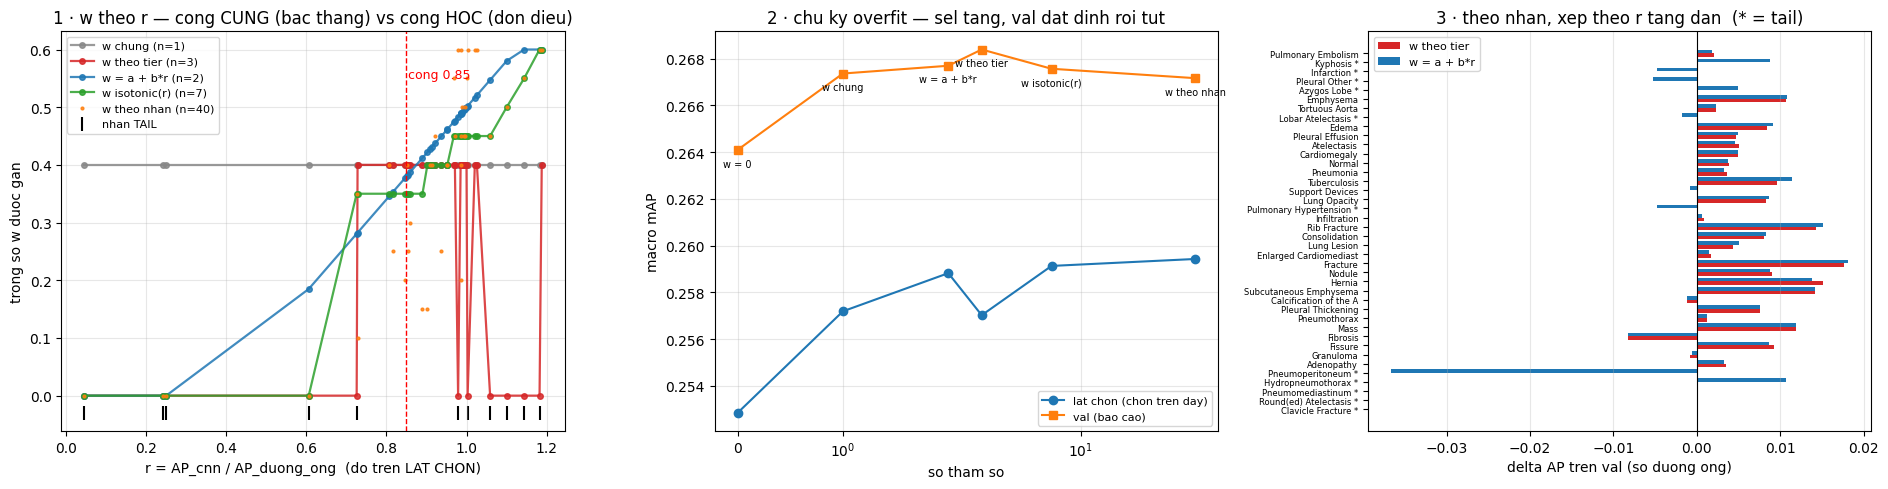


=== nhan ma `w = a + b*r` va `w theo tier` gan w KHAC NHAU nhat ===
nhan                             n+      r w w theo tier w w = a + b*rd AP w theo tierd AP w = a + b*r  tier
  Kyphosis                      112   1.18          0.00          0.60       +0.0000       +0.0088  TAIL
  Infarction                     96   1.14          0.00          0.60       +0.0000       -0.0048  TAIL
  Pleural Other                  80   1.10          0.00          0.58       +0.0000       -0.0053  TAIL
  Azygos Lobe                    20   1.06          0.00          0.55       +0.0000       +0.0050  TAIL
  Lobar Atelectasis              26   1.00          0.00          0.50       +0.0000       -0.0018  TAIL
  Pulmonary Hypertension        119   0.98          0.00          0.48       +0.0000       -0.0048  TAIL
  Pneumoperitoneum               54   0.73          0.00          0.28       +0.0000       -0.0367  TAIL
  Pulmonary Embolism            304   1.19          0.40          0.60       +0.0020   

In [ ]:
# ---- C9: CONG CUNG vs CONG HOC — hinh + nhan nao huong loi ----
import matplotlib; import matplotlib.pyplot as plt

_pa_ve = [k for k in ('w chung', 'w theo tier', 'w = a + b*r', 'w isotonic(r)', 'w theo nhan')
          if k in PA]
_mau = {'w chung': '#888888', 'w theo tier': '#d62728', 'w = a + b*r': '#1f77b4',
        'w isotonic(r)': '#2ca02c', 'w theo nhan': '#ff7f0e'}
_is_tail = np.zeros(C, bool); _is_tail[TIER['tail']] = True
_o = np.argsort(R_SL)

fig, ax = plt.subplots(1, 3, figsize=(19, 5))

# --- 1. w theo r ---
for k in _pa_ve:
    ax[0].plot(R_SL[_o], PA[k][_o], 'o-' if k != 'w theo nhan' else '.',
               ms=4, lw=1.6 if k != 'w theo nhan' else 0, alpha=0.85,
               color=_mau[k], label=f'{k} (n={KQ[k]["n"]})')
ax[0].scatter(R_SL[_is_tail], np.full(_is_tail.sum(), -0.03), marker='|', s=90,
              color='k', label='nhan TAIL')
ax[0].axvline(0.85, ls='--', c='r', lw=1)
ax[0].text(0.855, 0.55, 'cong 0.85', color='r', fontsize=9)
ax[0].set_xlabel('r = AP_cnn / AP_duong_ong  (do tren LAT CHON)')
ax[0].set_ylabel('trong so w duoc gan')
ax[0].set_title('1 · w theo r — cong CUNG (bac thang) vs cong HOC (don dieu)')
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

# --- 2. chu ky overfit theo bac tu do ---
_srt = sorted(KQ, key=lambda k: KQ[k]['n'])
_x = [KQ[k]['n'] for k in _srt]
ax[1].plot(_x, [KQ[k]['sel'] for k in _srt], 'o-', label='lat chon (chon tren day)')
ax[1].plot(_x, [KQ[k]['val'] for k in _srt], 's-', label='val (bao cao)')
for k in _srt:
    ax[1].annotate(k, (KQ[k]['n'], KQ[k]['val']), fontsize=7,
                   xytext=(0, -12), textcoords='offset points', ha='center')
ax[1].set_xscale('symlog'); ax[1].set_xlabel('so tham so')
ax[1].set_ylabel('macro mAP')
ax[1].set_title('2 · chu ky overfit — sel tang, val dat dinh roi tut')
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)

# --- 3. delta theo nhan, hai phuong an canh nhau ---
_A, _B = 'w theo tier', ('w = a + b*r' if 'w = a + b*r' in PA else 'w chung')
def _ap(wj):
    k = np.array([iW[float(min(WG, key=lambda x: abs(x - w)))] for w in wj])
    return TAB_VA[k, np.arange(C)]
dA, dB = _ap(PA[_A]) - AP_p_va, _ap(PA[_B]) - AP_p_va
_y = np.arange(C)
ax[2].barh(_y - 0.2, dA[_o], height=0.4, color=_mau[_A], label=_A)
ax[2].barh(_y + 0.2, dB[_o], height=0.4, color=_mau[_B], label=_B)
ax[2].set_yticks(_y)
ax[2].set_yticklabels([LAB40[c][:22] + (' *' if _is_tail[c] else '') for c in _o], fontsize=6)
ax[2].axvline(0, c='k', lw=0.8)
ax[2].set_xlabel('delta AP tren val (so duong ong)')
ax[2].set_title('3 · theo nhan, xep theo r tang dan  (* = tail)')
ax[2].legend(fontsize=8); ax[2].grid(alpha=0.3, axis='x')
fig.tight_layout()
try:
    _p = os.path.join(TMP_NPY, 'cong_cung_vs_hoc.png')   # TMP_NPY luon ton tai (dat o C0)
    fig.savefig(_p, dpi=110, bbox_inches='tight'); print(f'da ghi {_p}')
    ensure_res(); import shutil as _sh
    _sh.copy(_p, os.path.join(RES61, 'cong_cung_vs_hoc.png'))
except Exception as e:
    print(f'!! khong luu duoc hinh ({type(e).__name__})')
plt.show()

# ---- bang: nhan nao hai phuong an gan w KHAC NHAU nhat ----
_dw = PA[_B] - PA[_A]
print(f'\n=== nhan ma `{_B}` va `{_A}` gan w KHAC NHAU nhat ===')
print(f'{"nhan":<28}{"n+":>7}{"r":>7}{"w " + _A:>14}{"w " + _B:>14}'
      f'{"d AP " + _A:>14}{"d AP " + _B:>14}  tier')
for c in np.argsort(-np.abs(_dw))[:14]:
    print(f'  {LAB40[c]:<26}{int(Y_VA[:, c].sum()):>7}{R_SL[c]:>7.2f}'
          f'{PA[_A][c]:>14.2f}{PA[_B][c]:>14.2f}{dA[c]:>+14.4f}{dB[c]:>+14.4f}'
          f'  {"TAIL" if _is_tail[c] else ""}')

print(f'\n=== ai huong loi tu ai (tren val) ===')
_wa, _wb = dA - dB, dB - dA
print(f'  `{_A}` tot hon o {int((_wa > 0).sum())}/{C} nhan | tong {_wa[_wa > 0].sum():+.4f}')
print(f'  `{_B}` tot hon o {int((_wb > 0).sum())}/{C} nhan | tong {_wb[_wb > 0].sum():+.4f}')
for t, cols in TIER.items():
    print(f'    {t:<8} {_A}: {float(np.nanmean(dA[cols])):+.4f}'
          f'   |  {_B}: {float(np.nanmean(dB[cols])):+.4f}')
print('\n  Doc: cong CUNG zero-hoa CA tier tail (ke ca nhan r cao trong do); cong HOC zero-hoa')
print('  theo r nen giu lai nhan tail co r cao. Chenh lech giua hai cai nam DUNG o nhung nhan')
print('  ma prevalence va r KHONG trung nhau — bang tren liet ke chung.')

## C10 · `r` có đáng tin không — và co ngót `r` theo cỡ mẫu

`C9` lộ ra một chuyện `C8` không thấy: **`r` của cùng một nhãn, đo trên hai tập, khác nhau rất
nhiều**.

```
nhan                     r tren VAL (C6)   r tren LAT CHON (C9)
Infarction                    0.28              1.14      <- gap BON lan
Lobar Atelectasis             0.35              1.00
Pulmonary Hypertension        0.38              0.98
Pneumoperitoneum              0.32              0.73
```

Ba nhãn tail được cổng học gán `w` cao nhất (`0.48`–`0.60`) đều là ba nhãn `r` bị **thổi phồng**
mạnh nhất, và cả ba đều tụt trên val. Nên vấn đề **không phải dạng hàm** — `isotonic` đã cho thấy
bỏ giả định tuyến tính không mua được gì (`sel +0.0003`, `val −0.0001`). Vấn đề là **biến điều
kiện `r` không đo được** ở cỡ 19–154 ca dương.

**Phần 1 — chẩn đoán.** Tương quan `r_sel` vs `r_val` theo tier. Ở tail mà gần 0 thì **mọi** quy
tắc dựa trên `r` đều vô nghĩa ở tail, bất kể dạng hàm. Đó cũng là lý lẽ đo lường cho việc cổng
cứng thắng: nó điều kiện trên **prevalence** — đại lượng đếm được chính xác, không nhiễu.

**Phần 2 — chữa đúng bệnh.** Không thêm bậc tự do cho `f`, mà **co ngót biến**:

```
r~_j = (n_j * r_j + k * 1) / (n_j + k)          k chon tren LAT CHON

Clavicle Fracture  n=21,  r=0.07  ->  r~ ~ 0.84   (roi ve trong so chung)
Edema              n=900, r=1.00  ->  r~ = 1.00   (giu nguyen)
```

Thêm **một** tham số (`k`), không phải thêm độ linh hoạt. Và `k` tối ưu **tự nó là một phép đo**:
`k` lớn ⇒ `r` không đáng tin ở cỡ mẫu này; `k` → 0 ⇒ `r` dùng được như cũ.


In [ ]:
# ---- C10: DO TIN CUA r + co ngot theo co mau ----
from scipy.stats import spearmanr, pearsonr

R_VA = np.where(AP_p_va > 1e-9, AP_c_va / np.maximum(AP_p_va, 1e-9), 1.0)
R_VA = np.clip(np.nan_to_num(R_VA, nan=1.0), 0, 2)
N_SL = Y_SL.sum(0)

print('=== 1. DO TIN CUA r: r_sel vs r_val, theo tier ===')
print(f'  {"tier":<9}{"n nhan":>8}{"n+ sel TB":>11}{"spearman":>10}{"pearson":>9}'
      f'{"|r_sel-r_val| TB":>18}')
for t in ('head', 'medium', 'tail'):
    cols = TIER[t]
    sp = spearmanr(R_SL[cols], R_VA[cols]).statistic
    pe = pearsonr(R_SL[cols], R_VA[cols])[0]
    print(f'  {t:<9}{len(cols):>8}{N_SL[cols].mean():>11.0f}{sp:>10.3f}{pe:>9.3f}'
          f'{np.abs(R_SL[cols] - R_VA[cols]).mean():>18.3f}')
_sp_all = spearmanr(R_SL, R_VA).statistic
print(f'  {"ca 40":<9}{C:>8}{N_SL.mean():>11.0f}{_sp_all:>10.3f}')
_sp_tail = spearmanr(R_SL[TIER['tail']], R_VA[TIER['tail']]).statistic
if abs(_sp_tail) < 0.3:
    print(f'\n  -> tail: tuong quan {_sp_tail:+.3f} — `r` o tail gan nhu KHONG DO DUOC.')
    print('     MOI quy tac w = f(r) deu vo nghia o tail, bat ke dang ham.')
    print('     Cong CUNG thang vi no dieu kien tren PREVALENCE (dem chinh xac), khong tren r.')
else:
    print(f'\n  -> tail: tuong quan {_sp_tail:+.3f} — r co do tin nhat dinh, quy tac f(r) con cua.')

print(f'\n  nhan lech r nhieu nhat (|r_sel - r_val|):')
print(f'  {"nhan":<28}{"n+ sel":>8}{"r sel":>8}{"r val":>8}{"lech":>8}  tier')
for c in np.argsort(-np.abs(R_SL - R_VA))[:8]:
    print(f'  {LAB40[c]:<28}{int(N_SL[c]):>8}{R_SL[c]:>8.2f}{R_VA[c]:>8.2f}'
          f'{R_SL[c]-R_VA[c]:>+8.2f}  {"TAIL" if c in TIER["tail"] else ""}')

# ---- 2. co ngot r theo co mau, roi lap lai quet (a, b) ----
print('\n=== 2. `w = a + b*r~` voi r~ co ngot theo co mau ===')
_best = (None, -1)
for k_ in (0, 10, 25, 50, 100, 200, 400, 800, 1600):
    r_s = (N_SL * R_SL + k_ * 1.0) / (N_SL + k_)
    for a in np.round(np.arange(-0.40, 0.61, 0.05), 2):
        for b in np.round(np.arange(-0.60, 0.81, 0.05), 2):
            s = mac_w(TAB_SL, np.clip(a + b * r_s, 0, WG[-1]))
            if s > _best[1]: _best = ((k_, float(a), float(b)), s)
(_k, _a2, _b2), _s2 = _best
R_SHR = (N_SL * R_SL + _k * 1.0) / (N_SL + _k)
PA['w = a + b*r~'] = np.clip(_a2 + _b2 * R_SHR, 0, WG[-1])
print(f'  toi uu tren LAT CHON: k={_k}  a={_a2:+.2f}  b={_b2:+.2f}')
print(f'  r~ chay tu {R_SHR.min():.2f} den {R_SHR.max():.2f}'
      f'   (r goc: {R_SL.min():.2f} .. {R_SL.max():.2f})')
if _k >= 200:
    print(f'  -> k LON ({_k}): `r` khong dang tin o co mau nay; co ngot manh dua nhan hiem ve'
          ' trong so chung.')
elif _k == 0:
    print('  -> k = 0: co ngot KHONG giup, `r` tho da la lua chon tot nhat tren lat chon.')
else:
    print(f'  -> k = {_k}: co ngot vua phai.')

# so voi cac phuong an cu
_k_idx = np.array([iW[float(min(WG, key=lambda x: abs(x - w)))] for w in PA['w = a + b*r~']])
_v2 = float(np.nanmean(TAB_VA[_k_idx, np.arange(C)]))
_t2 = float(np.nanmean(TAB_VA[_k_idx, np.arange(C)][TIER['tail']]))
KQ['w = a + b*r~'] = dict(n=3, sel=_s2, val=_v2, d_val=_v2-BASE_V, tail=_t2, d_tail=_t2-BASE_TV)

print(f'\n  {"phuong an":<16}{"n":>4}{"sel":>9}{"val":>9}{"tail val":>10}')
for nm in sorted(KQ, key=lambda k: KQ[k]['n']):
    _m = ' <-- MOI' if nm == 'w = a + b*r~' else ''
    print(f'  {nm:<16}{KQ[nm]["n"]:>4}{KQ[nm]["sel"]:>9.4f}{KQ[nm]["val"]:>9.4f}'
          f'{KQ[nm]["tail"]:>10.4f}{_m}')
_ref2 = max((k for k in KQ if k != 'w theo nhan'), key=lambda k: KQ[k]['sel'])
print(f'\n  chon tren LAT CHON (bo moc overfit) -> `{_ref2}`')
print(f'  tot nhat tren val -> `{max(KQ, key=lambda k: KQ[k]["val"])}`')
_shr, _lin2 = KQ['w = a + b*r~'], KQ.get('w = a + b*r')
if _lin2:
    print(f'\n  co ngot - khong co ngot:  sel {_shr["sel"]-_lin2["sel"]:+.4f}'
          f'  |  val {_shr["val"]-_lin2["val"]:+.4f}'
          f'  |  tail {_shr["tail"]-_lin2["tail"]:+.4f}')

try:
    ensure_res()
    json.dump(dict(spearman_r_sel_val={t: float(spearmanr(R_SL[TIER[t]], R_VA[TIER[t]]).statistic)
                                       for t in TIER},
                   k=_k, a=_a2, b=_b2, ket_qua={k: v for k, v in KQ.items()}),
              open(os.path.join(RES61, 'do_tin_r.json'), 'w'), indent=1)
    print('\nda ghi ' + os.path.join(RES61, 'do_tin_r.json'))
except Exception as e:
    print(f'\n!! ghi Drive that bai ({type(e).__name__})')

=== 1. DO TIN CUA r: r_sel vs r_val, theo tier ===
  tier       n nhan  n+ sel TB  spearman  pearson  |r_sel-r_val| TB
  head           13       6575     0.621    0.826             0.018
  medium         16        535     0.635    0.545             0.083
  tail           11         74     0.218    0.225             0.416
  ca 40          40       2371     0.297

  -> tail: tuong quan +0.218 — `r` o tail gan nhu KHONG DO DUOC.
     MOI quy tac w = f(r) deu vo nghia o tail, bat ke dang ham.
     Cong CUNG thang vi no dieu kien tren PREVALENCE (dem chinh xac), khong tren r.

  nhan lech r nhieu nhat (|r_sel - r_val|):
  nhan                          n+ sel   r sel   r val    lech  tier
  Infarction                       135    1.14    0.28   +0.87  TAIL
  Pneumomediastinum                 80    0.25    0.90   -0.65  TAIL
  Lobar Atelectasis                 20    1.00    0.35   +0.65  TAIL
  Pulmonary Hypertension           154    0.98    0.38   +0.60  TAIL
  Pleural Other                 

## C11 · Điều kiện `w` trên **độ đa dạng**, không trên `r`

`C10` cho thấy `r = AP_cnn / AP_ống` **không đo được ở tail**: `spearman(r_sel, r_val) = 0.218`,
sai số đo `0.416` trên thang chỉ rộng `1.1`. Lý do cấu trúc: `r` là **tỉ số hai ước lượng nhiễu**,
cả hai ước từ cùng nhúm 19–154 ca dương.

Biến thay thế **không có nhược điểm đó**:

```
rho_j = spearman( p_duong_ong[:, j] , p_cnn[:, j] )   tren TOAN BO anh val
```

Ba khác biệt quyết định:

```
r      can NHAN  ->  co mau = so ca DUONG  (19-154 o tail)   ->  nhieu nang
rho    KHONG can nhan  ->  co mau = so ANH (39,293)          ->  nhieu rat nho
```

Và `rho` là đại lượng mà **lý thuyết ensemble** thực sự nói tới: lợi ích của việc trộn đến từ
**độ đa dạng** (`1 − rho`), không từ độ mạnh tương đối. Trộn hai mô hình gần trùng nhau thì
không được gì dù cả hai đều mạnh.

Cell này:

```
1. do rho theo nhan, kiem DO TIN cua no: rho tren nua A vs nua B cua val (chia theo BENH NHAN)
   -> so truc tiep voi spearman(r_sel, r_val) = 0.218 cua `r`
2. w = a + b*rho   (2 tham so, chon tren LAT CHON) -> vao thang so sanh
3. tuong quan(rho, delta) — `rho` co giai thich duoc delta khong, so voi r (+0.598)
```

**Điều cần cẩn thận:** `rho` đo trên val nhưng **không dùng nhãn val**, nên không phải rò rỉ nhãn.
Dù vậy cell vẫn đo `rho` trên **lát chọn** để chọn `w`, giữ nguyên kỷ luật — bản trên val chỉ dùng
để kiểm độ tin.


In [ ]:
# ---- C11: dieu kien w tren TUONG QUAN DU DOAN (khong can nhan) ----
from scipy.stats import spearmanr

def _rho_theo_nhan(A, B):
    # spearman theo tung cot, KHONG dung nhan -> co mau = so ANH, khong phai so ca duong
    from scipy.stats import rankdata
    ra, rb = rankdata(A, axis=0), rankdata(B, axis=0)
    ra = (ra - ra.mean(0)) / (ra.std(0) + 1e-12)
    rb = (rb - rb.mean(0)) / (rb.std(0) + 1e-12)
    return (ra * rb).mean(0)

RHO_SL = _rho_theo_nhan(PS_P, CS)          # tren LAT CHON  -> dung de CHON w
RHO_VA = _rho_theo_nhan(PV_P, CV)          # tren val       -> chi de kiem do tin

# --- 1. DO TIN: chia val lam hai nua theo BENH NHAN roi do lai ---
_u = np.unique(SUB_VA); _rs = np.random.default_rng(11)
_pa = set(_rs.choice(_u, len(_u)//2, replace=False))
_mA = np.array([s in _pa for s in SUB_VA]); _mB = ~_mA
RHO_A = _rho_theo_nhan(PV_P[_mA], CV[_mA])
RHO_B = _rho_theo_nhan(PV_P[_mB], CV[_mB])

print('=== 1. DO TIN cua `rho` (chia val lam hai nua theo BENH NHAN) ===')
print(f'  {"tier":<9}{"spearman(rho_A, rho_B)":>24}{"|rho_A-rho_B| TB":>19}'
      f'{"  (nho lai: r la)":>18}')
_r_tin = {'head': 0.621, 'medium': 0.635, 'tail': 0.218}
for t in ('head', 'medium', 'tail'):
    cols = TIER[t]
    sp = spearmanr(RHO_A[cols], RHO_B[cols]).statistic
    print(f'  {t:<9}{sp:>24.3f}{np.abs(RHO_A[cols]-RHO_B[cols]).mean():>19.3f}'
          f'{_r_tin[t]:>18.3f}')
_sp_t = spearmanr(RHO_A[TIER['tail']], RHO_B[TIER['tail']]).statistic
print(f'\n  rho o TAIL: do tin {_sp_t:+.3f}  vs  r o tail {_r_tin["tail"]:+.3f}')
if _sp_t > _r_tin['tail'] + 0.15:
    print('  -> `rho` DO DUOC o tail trong khi `r` thi khong. Dung `rho` lam bien dieu kien.')
elif _sp_t > _r_tin['tail']:
    print('  -> `rho` on dinh hon `r` mot chut, nhung chua du de doi han.')
else:
    print('  -> `rho` KHONG on dinh hon `r`. Gia thiet cua ta sai; xem lai.')

print(f'\n  {"nhan":<28}{"n+":>7}{"rho sel":>9}{"rho val":>9}{"r sel":>8}  tier')
for c in np.argsort(RHO_SL)[:8]:
    print(f'  {LAB40[c]:<28}{int(Y_VA[:, c].sum()):>7}{RHO_SL[c]:>9.3f}{RHO_VA[c]:>9.3f}'
          f'{R_SL[c]:>8.2f}  {"TAIL" if c in TIER["tail"] else ""}')

# --- 2. w = a + b*rho, chon tren LAT CHON ---
_bst = (None, -1)
for a in np.round(np.arange(-0.60, 1.01, 0.05), 2):
    for b in np.round(np.arange(-1.20, 1.21, 0.05), 2):
        s = mac_w(TAB_SL, np.clip(a + b * RHO_SL, 0, WG[-1]))
        if s > _bst[1]: _bst = ((float(a), float(b)), s)
(_a3, _b3), _s3 = _bst
PA['w = a + b*rho'] = np.clip(_a3 + _b3 * RHO_SL, 0, WG[-1])
_ki = np.array([iW[float(min(WG, key=lambda x: abs(x - w)))] for w in PA['w = a + b*rho']])
_v3 = float(np.nanmean(TAB_VA[_ki, np.arange(C)]))
_t3 = float(np.nanmean(TAB_VA[_ki, np.arange(C)][TIER['tail']]))
KQ['w = a + b*rho'] = dict(n=2, sel=_s3, val=_v3, d_val=_v3-BASE_V, tail=_t3, d_tail=_t3-BASE_TV)

print(f'\n=== 2. `w = a + b*rho` toi uu tren LAT CHON: a={_a3:+.2f}  b={_b3:+.2f} ===')
print(f'  rho chay tu {RHO_SL.min():.3f} den {RHO_SL.max():.3f}'
      f'  ->  w tu {PA["w = a + b*rho"].min():.2f} den {PA["w = a + b*rho"].max():.2f}')
if _b3 < 0:
    print('  b AM: rho THAP (hai mo hinh KHAC nhau) -> tron NHIEU. Khop ly thuyet ensemble:')
    print('        loi ich den tu DO DA DANG, khong tu do manh tuong doi.')
elif _b3 > 0:
    print('  b DUONG: rho CAO -> tron nhieu. NGUOC ly thuyet da dang; doc than trong.')

# --- 3. rho co giai thich duoc delta khong ---
_D_g = ap_cols(Y_VA, (1-w_g)*PV_P + w_g*CV) - AP_p_va
_sp_rho = spearmanr(RHO_VA, _D_g)
print(f'\n=== 3. Spearman(rho, delta o w chung) = {_sp_rho.statistic:+.3f}'
      f'  p = {_sp_rho.pvalue:.4f}   (r cho +0.598) ===')

print(f'\n  {"phuong an":<16}{"n":>4}{"sel":>9}{"val":>9}{"tail val":>10}')
for nm in sorted(KQ, key=lambda k: KQ[k]['n']):
    _m = ' <-- MOI' if nm == 'w = a + b*rho' else ''
    print(f'  {nm:<16}{KQ[nm]["n"]:>4}{KQ[nm]["sel"]:>9.4f}{KQ[nm]["val"]:>9.4f}'
          f'{KQ[nm]["tail"]:>10.4f}{_m}')
_ref3 = max((k for k in KQ if k != 'w theo nhan'), key=lambda k: KQ[k]['sel'])
print(f'\n  chon tren LAT CHON (bo moc overfit) -> `{_ref3}`')
print(f'  tot nhat tren val -> `{max(KQ, key=lambda k: KQ[k]["val"])}`')

try:
    ensure_res()
    json.dump(dict(a=_a3, b=_b3, do_tin_rho={t: float(spearmanr(RHO_A[TIER[t]],
                                                                RHO_B[TIER[t]]).statistic)
                                             for t in TIER},
                   spearman_rho_delta=float(_sp_rho.statistic),
                   ket_qua={k: v for k, v in KQ.items()}),
              open(os.path.join(RES61, 'w_theo_rho.json'), 'w'), indent=1)
    print('\nda ghi ' + os.path.join(RES61, 'w_theo_rho.json'))
except Exception as e:
    print(f'\n!! ghi Drive that bai ({type(e).__name__})')

=== 1. DO TIN cua `rho` (chia val lam hai nua theo BENH NHAN) ===
  tier       spearman(rho_A, rho_B)   |rho_A-rho_B| TB   (nho lai: r la)
  head                        0.995              0.003             0.621
  medium                      0.997              0.007             0.635
  tail                        1.000              0.008             0.218

  rho o TAIL: do tin +1.000  vs  r o tail +0.218
  -> `rho` DO DUOC o tail trong khi `r` thi khong. Dung `rho` lam bien dieu kien.

  nhan                             n+  rho sel  rho val   r sel  tier
  Infarction                       96    0.593    0.590    1.14  TAIL
  Subcutaneous Emphysema          431    0.636    0.630    0.90  
  Hernia                          674    0.662    0.661    0.91  
  Pneumoperitoneum                 54    0.666    0.687    0.73  TAIL
  Pulmonary Embolism              304    0.672    0.669    1.19  
  Clavicle Fracture                19    0.703    0.717    0.05  TAIL
  Fibrosis                     

In [ ]:
# ==== LUOI SO SANH: do sau epoch x phuong an trong so — MOI o tinh lai tu dau ====
TE = ~(TR | VA); Y_TE = YM[TE]
_load = _local_npy if '_local_npy' in dir() else (lambda p: p)
THANH_VIEN = 'cnn_full'
NGUONG = 0.85

def _keys(pre, name):
    out = {}
    for d, arm in SRC[name]:
        for f in sorted(glob.glob(os.path.join(d, f'{pre}_{arm}_s*_ep*.npy'))):
            m = re.search(r'_s(\d+)_ep(\d+)\.npy$', os.path.basename(f))
            if m: out[(arm, m.group(1), m.group(2))] = f
    return out

def _gop(d, ks):
    return np.mean([np.load(_load(d[k])).astype('float32') for k in ks], 0)

kv_p, ks_p, kt_p = _keys('p', 'pipe'), _keys('psl', 'pipe'), _keys('pte', 'pipe')
kv_c, ks_c, kt_c = (_keys('p', THANH_VIEN), _keys('psl', THANH_VIEN), _keys('pte', THANH_VIEN))
FULL_P = sorted(set(kv_p) & set(ks_p));  FULL_C = sorted(set(kv_c) & set(ks_c))
KHOP_P = sorted(set(kv_p) & set(ks_p) & set(kt_p))
KHOP_C = sorted(set(kv_c) & set(ks_c) & set(kt_c))
print(f'tap DAY DU : pipe {len(FULL_P)} epoch-seed | {THANH_VIEN} {len(FULL_C)}   (khong co test)')
print(f'tap KHOP   : pipe {len(KHOP_P)} epoch-seed | {THANH_VIEN} {len(KHOP_C)}   (co ca test)')

TAP = {
 'day du': dict(pv=_gop(kv_p, FULL_P), ps=_gop(ks_p, FULL_P), pt=None,
                cv=_gop(kv_c, FULL_C), cs=_gop(ks_c, FULL_C), ct=None),
 'khop 3ep': dict(pv=_gop(kv_p, KHOP_P), ps=_gop(ks_p, KHOP_P), pt=_gop(kt_p, KHOP_P),
                  cv=_gop(kv_c, KHOP_C), cs=_gop(ks_c, KHOP_C), ct=_gop(kt_c, KHOP_C)),
}

def _w_chung(ps, cs):
    return float(WG[int(np.argmax([mac(Y_SL, (1-w)*ps + w*cs) for w in WG]))])

def _w_tier(ps, cs):
    ap_p, ap_c = ap_cols(Y_SL, ps), ap_cols(Y_SL, cs)
    wt, tl = {}, {}
    for t, cols in TIER.items():
        tl[t] = float(np.nanmean(ap_c[cols])) / max(float(np.nanmean(ap_p[cols])), 1e-9)
        if tl[t] < NGUONG:
            wt[t] = 0.0
        else:
            sc = [(w, float(np.nanmean(ap_cols(Y_SL, (1-w)*ps + w*cs)[cols]))) for w in WG]
            wt[t] = float(max(sc, key=lambda z: z[1])[0])
    return wt, tl

def _ap(Y, P, cols): return float(np.nanmean(ap_cols(Y, P)[cols]))

print(f'\n{"tap epoch":<11}{"phuong an":<20}{"trong so":>16}'
      f'{"val macro":>11}{"val head":>10}{"val med":>9}{"val tail":>10}'
      f'{"test macro":>12}{"test tail":>11}')
KQ_L = {}
for ten, D in TAP.items():
    pv, ps, pt, cv, cs, ct = D['pv'], D['ps'], D['pt'], D['cv'], D['cs'], D['ct']
    wg_ = _w_chung(ps, cs)
    wt_, tl_ = _w_tier(ps, cs)
    def _mix(P_o, P_c, wt):
        Q = np.array(P_o, copy=True)
        for t, cols in TIER.items(): Q[:, cols] = (1-wt[t])*P_o[:, cols] + wt[t]*P_c[:, cols]
        return Q
    PHA = [('duong ong', '-', pv, pt),
           ('w chung', f'{wg_:.2f}', (1-wg_)*pv + wg_*cv,
            None if pt is None else (1-wg_)*pt + wg_*ct),
           ('w theo tier', '/'.join(f'{wt_[t]:.2f}' for t in ('head','medium','tail')),
            _mix(pv, cv, wt_), None if pt is None else _mix(pt, ct, wt_))]
    for nm, ws, Pv, Pt in PHA:
        row = (f'  {ten:<9}{nm:<20}{ws:>16}'
               f'{_ap(Y_VA, Pv, np.arange(C)):>11.4f}{_ap(Y_VA, Pv, TIER["head"]):>10.4f}'
               f'{_ap(Y_VA, Pv, TIER["medium"]):>9.4f}{_ap(Y_VA, Pv, TIER["tail"]):>10.4f}')
        if Pt is None: row += f'{"-":>12}{"-":>11}'
        else: row += (f'{_ap(Y_TE, Pt, np.arange(C)):>12.4f}'
                      f'{_ap(Y_TE, Pt, TIER["tail"]):>11.4f}')
        print(row)
        KQ_L[(ten, nm)] = dict(val=_ap(Y_VA, Pv, np.arange(C)),
                               tail=_ap(Y_VA, Pv, TIER['tail']),
                               test=None if Pt is None else _ap(Y_TE, Pt, np.arange(C)))
    print(f'  {"":<9}ti le muc tier: '
          + ' | '.join(f'{t}={tl_[t]:.2f}' for t in ('head', 'medium', 'tail')))

g = lambda a, b: KQ_L[(a, b)]
print('\n=== TACH HAI TAC NHAN (tren val macro) ===')
_e = g('day du', 'duong ong')['val'] - g('khop 3ep', 'duong ong')['val']
print(f'  A. them epoch (3 -> 10), nen duong ong          : {_e:+.4f}')
for tap in ('day du', 'khop 3ep'):
    _c1 = g(tap, 'w chung')['val'] - g(tap, 'duong ong')['val']
    _c2 = g(tap, 'w theo tier')['val'] - g(tap, 'duong ong')['val']
    print(f'  B. blend o tap `{tap}`:  w chung {_c1:+.4f}  |  w theo tier {_c2:+.4f}'
          f'  (chenh {_c2-_c1:+.4f})')

_kt = g('khop 3ep', 'w theo tier'); _kp = g('khop 3ep', 'duong ong')
if _kt['test'] is not None:
    _dv = _kt['val'] - _kp['val']; _dt = _kt['test'] - _kp['test']
    print(f'\n=== CHUYEN GIAO (chi doc duoc o tap KHOP, vi test chi co 3 epoch) ===')
    print(f'  d val {_dv:+.4f}  vs  d test {_dt:+.4f}   lech {_dt-_dv:+.4f}')
print(f'\n  CON SO BAO CAO cho cau hinh trien khai = dong `day du / w theo tier`:'
      f' {g("day du", "w theo tier")["val"]:.4f}')


tap DAY DU : pipe 20 epoch-seed | cnn_full 16   (khong co test)
tap KHOP   : pipe 6 epoch-seed | cnn_full 6   (co ca test)

tap epoch  phuong an                   trong so  val macro  val head  val med  val tail  test macro  test tail
  day du   duong ong                          -     0.2641    0.4758   0.1942    0.1155           -          -
  day du   w chung                         0.40     0.2674    0.4811   0.2007    0.1117           -          -
  day du   w theo tier           0.40/0.40/0.00     0.2684    0.4811   0.2007    0.1155           -          -
           ti le muc tier: head=0.97 | medium=0.90 | tail=0.68
  khop 3ep duong ong                          -     0.2562    0.4703   0.1860    0.1053      0.2495     0.0897
  khop 3ep w chung                         0.45     0.2637    0.4789   0.1973    0.1061      0.2572     0.0913
  khop 3ep w theo tier           0.45/0.45/0.00     0.2635    0.4789   0.1973    0.1053      0.2567     0.0897
           ti le muc tier: head=0.98

## C12 · Thành viên CNN @1022 vào ensemble — có ăn không? (0 GPU)

`68b` cho thành viên CNN mạnh hơn `+0.0057` macro. Câu hỏi **không** phải là thành viên
có mạnh hơn không, mà là **ensemble** có mạnh lên không. Hai thứ đó khác nhau: nếu phần
mạnh thêm trùng với chỗ đường ống vốn đã làm tốt, blend sẽ không nhận được gì.

Cái bẫy phải tránh: `68b` mới có **6 file** (`E=6`, seed 42) còn `64b` có **16**
(`E=8`, 2 seed). So thẳng hai cái đó là trộn lẫn hai thay đổi — độ phân giải *và* cỡ
ensemble. Nên cell này dựng thêm bản `64b` **lọc về đúng 6 file** để làm đối chứng.

Đọc dòng `(4) − (3)`. Đó mới là tác dụng của độ phân giải lên ensemble.


In [ ]:
# ==== C12 · 68b @1022 vao ensemble co an khong — 0 GPU, chi can C0 ====
import glob as _g12, re as _re12, shutil as _sh12


def _doc12(p):
    '''Copy ve /content roi doc. Doc THANG tren mount FUSE la nguon goc
       `OSError 107 Transport endpoint is not connected` (da dinh 8 lan).'''
    lp = os.path.join(TMP_NPY, p.replace(os.sep, '_').replace(':', '_').lstrip('_'))
    sz = os.path.getsize(p)
    if os.path.exists(lp) and os.path.getsize(lp) == sz: return lp
    _sh12.copy(p, lp)
    assert os.path.getsize(lp) == sz, f'copy NGAN tu Drive: {p}'
    return lp


def _nap12(goc, run, arm, nhan, seeds=None, ep_toi=None):
    '''Trung binh xac suat tren VAL. KHONG doi hoi `psl_`: R2a da gop lat chon vao train
       nen cac luot 64/64b/68b khong con ghi file do.'''
    uq = {}
    for d in _mau(goc, run):
        for f in sorted(_g12.glob(os.path.join(d, f'p_{arm}_s*_ep*.npy'))):
            m = _re12.search(r'_s(\d+)_ep(\d+)\.npy$', os.path.basename(f))
            if not m: continue
            sd, ep = int(m.group(1)), int(m.group(2))
            if seeds is not None and sd not in seeds: continue
            if ep_toi is not None and ep > ep_toi: continue
            uq.setdefault(os.path.basename(f), f)     # thu muc Drive trung ten -> khong dem 2 lan
    assert uq, f'{nhan}: khong thay file nao o {goc}/{run} (arm `{arm}`)'
    Q = np.mean([np.load(_doc12(f)).astype('float32') for f in uq.values()], 0)
    assert Q.shape == (int(VA.sum()), C), f'{nhan}: hinh dang {Q.shape}'
    print(f'  {nhan:<34}{len(uq):>3} file')
    return Q, len(uq)


# `68b` ghi luot THU vao `r1022` va luot DAY DU vao `r1022_E8`. Uu tien ban day du
# neu da co — neu khong se im lang doc 6 file cu sau khi da tieu 46 gio GPU.
TAG1022 = 'r1022_E8' if len(_mau('stage4_nb68b', 'r1022_E8')) else 'r1022'
print(f'luot 68b dang doc: {TAG1022}'
      + ('   (DAY DU E=8)' if TAG1022.endswith('_E8') else '   (luot THU E=6, 1 seed)'))

print('nap du doan VAL:')
PIPE, nP = _nap12('stage4_nb64',  'r2a',   'tpb',      'duong ong 64/r2a')
C518, n5 = _nap12('stage4_nb64b', 'r2a',   'cnn_full', 'cnn 64b @518 (day du)')
C1022, n1 = _nap12('stage4_nb68b', TAG1022, 'cnn_full', f'cnn 68b @1022 ({TAG1022})')

# --- doi chung KHOP NGAN SACH: 64b loc ve dung seed/epoch ma 68b co ---
_sd = sorted({int(_re12.search(r'_s(\d+)_ep', os.path.basename(f)).group(1))
              for d in _mau('stage4_nb68b', TAG1022)
              for f in _g12.glob(os.path.join(d, 'p_cnn_full_s*_ep*.npy'))})
_ep = max(int(_re12.search(r'_ep(\d+)\.npy$', os.path.basename(f)).group(1))
          for d in _mau('stage4_nb68b', TAG1022)
          for f in _g12.glob(os.path.join(d, 'p_cnn_full_s*_ep*.npy')))
C518M, n5m = _nap12('stage4_nb64b', 'r2a', 'cnn_full',
                    f'cnn 64b @518 (KHOP: seed {_sd}, ep<={_ep})', seeds=set(_sd), ep_toi=_ep)
assert n5m == n1, (f'doi chung {n5m} file vs 68b {n1} file -> CHUA khop ngan sach, '
                   'moi so so sanh sau day deu tron lan hai thay doi')

# --- tron theo tier, trong so KHOA TRUOC ---
W12 = {'head': 0.40, 'medium': 0.40, 'tail': 0.00}


def tron12(pipe, cnn, w=W12):
    Q = pipe.copy()
    for t, idx in TIER.items():
        Q[:, idx] = (1 - w[t]) * pipe[:, idx] + w[t] * cnn[:, idx]
    return Q


_cfg = [('(1) duong ong mot minh',              PIPE),
        (f'(2) + cnn @518 day du ({n5} file)',  tron12(PIPE, C518)),
        (f'(3) + cnn @518 KHOP ({n5m} file)',   tron12(PIPE, C518M)),
        (f'(4) + cnn @1022    ({n1} file)',     tron12(PIPE, C1022))]

print(f'\nVAL — thang tier cua nb61 (INV, tuc thang CU 13/16/11; macro thi khong doi thang)')
print(f'{"cau hinh":<34}{"macro":>9}{"head":>9}{"medium":>9}{"tail":>9}')
_R12 = {}
for nm, Q in _cfg:
    a = ap_cols(Y_VA, Q); _R12[nm] = a
    tr = {t: float(np.nanmean(a[i])) for t, i in TIER.items()}
    print(f'  {nm:<32}{np.nanmean(a):>9.4f}' + ''.join(f'{tr[t]:>9.4f}' for t in tr))

_k3, _k4 = _cfg[2][0], _cfg[3][0]
D12 = float(np.nanmean(_R12[_k4]) - np.nanmean(_R12[_k3]))
D12_2 = float(np.nanmean(_R12[_k4]) - np.nanmean(_R12[_cfg[1][0]]))
print(f'\n  (4) - (3)  do phan giai, KHOP ngan sach : {D12:+.4f}   <- doc dong NAY')
print(f'  (4) - (2)  so voi ban dang trien khai   : {D12_2:+.4f}   (tron lan ca co ensemble)')

# --- bootstrap ghep cap theo benh nhan cho dong (4)-(3) ---
_sv = SUB[np.where(VA)[0]]; _u12 = np.unique(_sv)
_ix = {s: np.where(_sv == s)[0] for s in _u12}
_rs12 = np.random.default_rng(612); _bs12 = []
for _ in range(200):
    _p12 = np.concatenate([_ix[s] for s in _rs12.choice(_u12, len(_u12), replace=True)])
    _bs12.append(float(np.nanmean(ap_cols(Y_VA[_p12], _cfg[3][1][_p12]))
                       - np.nanmean(ap_cols(Y_VA[_p12], _cfg[2][1][_p12]))))
_lo12, _hi12 = np.percentile(_bs12, [2.5, 97.5])
print(f'  bootstrap 200 lan, ghep cap theo benh nhan: {D12:+.4f} CI95 [{_lo12:+.4f}, {_hi12:+.4f}]')

# --- `w` khoa tu 2026-08 con dung cho thanh vien @1022 khong? ---
print(f'\nquet `w` tren VAL cho cau hinh (4) — val gio la tap chon hop le:')
_best = (None, -1)
for _w in np.round(np.arange(0.0, 0.81, 0.05), 2):
    _m = float(np.nanmean(ap_cols(Y_VA, tron12(PIPE, C1022,
                                               {'head': _w, 'medium': _w, 'tail': 0.0}))))
    if _m > _best[1]: _best = (_w, _m)
    print(f'    w={_w:.2f}  {_m:.4f}' + ('  *' if _w == 0.40 else ''))
print(f'  dinh w={_best[0]:.2f} ({_best[1]:.4f}) | w khoa 0.40 cho '
      f'{float(np.nanmean(_R12[_k4])):.4f}  chenh {_best[1]-float(np.nanmean(_R12[_k4])):+.4f}')

print('\n' + '=' * 74)
SAN12 = 0.0007
if _lo12 > SAN12:
    print(f'-> ENSEMBLE CO LEN ({D12:+.4f}, can duoi {_lo12:+.4f} > san {SAN12}).')
    print('   Dang dong tien: chay 68b day du E=8, 2 seed (~46 gio GPU) roi thay cnn_full.')
elif _hi12 < SAN12:
    print(f'-> Thanh vien manh hon nhung ENSEMBLE KHONG len (CI95 nam duoi san {SAN12}).')
    print('   Van de o TRONG SO TRON, khong o do phan giai. Quet lai `w` truoc, re hon 46 gio.')
else:
    print(f'-> CHUA KET LUAN (CI chua san {SAN12}). 6 file la qua it de doc chac.')
    print('   Re nhat: chay them 68b seed 43 o E=6 (~17 gio) roi do lai, thay vi nhay len E=8.')
print('KHONG cham test o cell nay.')
print('=' * 74)


## C13 · Ba chiều `pipe ⊕ cnn@518 ⊕ cnn@1022` — hai CNN sai ở nhãn khác nhau (0 GPU)

Chạy **sau C12**. Ở 16 vs 16 file, 1022 gần hoà 518 về macro nhưng **đổi chỗ theo nhãn**:
`Granuloma +0.0665`, `Hydropneumothorax +0.0468` đối lại `Mass −0.0267`, `Hernia −0.0261`.
Lợi/hại nằm trong cùng tier nên trọng số theo tier không tách được — nhưng trộn **cả hai** CNN
thì có thể. Khác `cnn_ms` (đa dạng theo tầng, đã trượt ở `67`): đây là đa dạng theo độ phân giải.
Tail giữ `w=0` như cấu hình khoá.


In [ ]:
# ==== C13 · ba chieu, quet (w1, w2) tren VAL — can PIPE, C518, C1022 tu C12 ====
for _n in ('PIPE', 'C518', 'C1022', 'tron12'):
    assert _n in globals(), f'chay C12 truoc: thieu {_n}'


def tron3(w1, w2):
    Q = PIPE.copy()
    for t, idx in TIER.items():
        if t == 'tail': continue                      # tail: w = 0 nhu cau hinh khoa
        Q[:, idx] = (1 - w1 - w2) * PIPE[:, idx] + w1 * C518[:, idx] + w2 * C1022[:, idx]
    return Q


_G = np.round(np.arange(0.0, 0.61, 0.05), 2)
_S = {}
for w1 in _G:
    for w2 in _G:
        if w1 + w2 > 0.70: continue
        _S[(w1, w2)] = float(np.nanmean(ap_cols(Y_VA, tron3(w1, w2))))
(_b1, _b2), _bm = max(_S.items(), key=lambda kv: kv[1])
_ref = {'(2) pipe + cnn518 w=.40 (trien khai)': _S[(0.40, 0.0)],
        '(4) pipe + cnn1022 w=.40':             _S[(0.0, 0.40)],
        f'(5) BA CHIEU w1={_b1:.2f} w2={_b2:.2f}': _bm}
print('VAL, macro:')
for k, v in _ref.items(): print(f'  {k:<42}{v:.4f}')
_cn = [k for k, v in _S.items() if _bm - v <= 5e-4]
print(f'  cao nguyen (trong 0.0005): {len(_cn)}/{len(_S)} diem  '
      f'w1 in [{min(k[0] for k in _cn):.2f},{max(k[0] for k in _cn):.2f}]  '
      f'w2 in [{min(k[1] for k in _cn):.2f},{max(k[1] for k in _cn):.2f}]')

# bootstrap ghep cap theo benh nhan: (5) - (2)
_Q5, _Q2 = tron3(_b1, _b2), tron3(0.40, 0.0)
_sv = SUB[np.where(VA)[0]]; _u = np.unique(_sv); _ix = {s: np.where(_sv == s)[0] for s in _u}
_rs = np.random.default_rng(613); _bs = []
for _ in range(200):
    _p = np.concatenate([_ix[s] for s in _rs.choice(_u, len(_u), replace=True)])
    _bs.append(float(np.nanmean(ap_cols(Y_VA[_p], _Q5[_p])) - np.nanmean(ap_cols(Y_VA[_p], _Q2[_p]))))
_lo, _hi = np.percentile(_bs, [2.5, 97.5])
_d = _bm - _S[(0.40, 0.0)]
print()
print(f'(5) - (2): {_d:+.4f}  CI95 [{_lo:+.4f}, {_hi:+.4f}]   (w chon TREN val -> lac quan; doc CI)')
_a5, _a2 = ap_cols(Y_VA, _Q5), ap_cols(Y_VA, _Q2)
for t, i in TIER.items():
    print(f'  {t:<8}{np.nanmean(_a2[i]):>9.4f} -> {np.nanmean(_a5[i]):<9.4f}'
          f'{np.nanmean(_a5[i]) - np.nanmean(_a2[i]):>+9.4f}')
print()
print('=' * 70)
if _lo > 0.0007:
    print(f'-> BA CHIEU CO AN (can duoi {_lo:+.4f} > san 0.0007). Thanh vien 1022 dang gia giu.')
elif _hi < 0.0007:
    print('-> khong an. Dong "1022 thay/them vao cnn_full".')
else:
    print('-> chua ket luan (CI chua san). w chon tren val nen can co ngot.')
print('KHONG cham test.')


## C14 · Chạm TEST — **một lần đọc cho cả bảng**

`nb61` không có model, chỉ đọc `.npy`. Nên suy luận sinh `pte_` phải chạy ở `64`/`64b`/`68b`;
cell này chỉ **trộn và chấm**.

Cần trước khi chạy:

| Nguồn | Sinh ở đâu | Thư mục |
|---|---|---|
| đường ống, XGB mới | `nb69` C8 | `stage4_nb69/` |
| cnn@518, XGB mới | `64b` + cell suy luận | `stage4_nb64b/r2a_xgbnew/` |
| cnn@1022, XGB mới | `68b` + cell suy luận | `stage4_nb68b/r1022_E8_xgbnew/` |

Để `DOC_TEST = False` thì cell chỉ **kiểm kê file** rồi dừng, không tốn lần chạm nào.
Bật `True` là đọc nhãn test, tính **một lần** cho cả bảng và ghi vào `_test_touches_nb61.jsonl`.


In [ ]:
# ==== C14 · CHAM TEST: XGB cu vs moi, 2 chieu vs 3 chieu — MOT LAN cho ca bang ====
DOC_TEST = False        # False: chi kiem ke file, KHONG cham. True: doc nhan test (ton 1 lan).

import glob as _g14, shutil as _s14, datetime as _dt14
TE14 = ~(TR | VA); Y_TE14 = YM[TE14]; SUB_TE14 = SUB[TE14]


def _dirs14(goc, run):
    """Thu muc that + moi ban trung ten (Drive FUSE de ra goc (1) / run (1))."""
    out = []
    for x in sorted(os.listdir(OUT_DIR)):
        if not (x == goc or x.startswith(goc + ' (')): continue
        base = os.path.join(OUT_DIR, x)
        if not run:
            out.append(base); continue
        for y in sorted(os.listdir(base)):
            if (y == run or y.startswith(run + ' (')) and os.path.isdir(os.path.join(base, y)):
                out.append(os.path.join(base, y))
    return out


def _nap_te(goc, run, arm, nhan):
    uq = {}
    for d in _dirs14(goc, run):
        for f in sorted(_g14.glob(os.path.join(d, f'pte_{arm}_s*_ep*.npy'))):
            uq.setdefault(os.path.basename(f), f)        # trung ten -> dem MOT lan
    if not uq:
        print(f'  {nhan:<26}  THIEU  ({goc}/{run})'); return None, 0
    Q = np.mean([np.load(_local_npy(f) if '_local_npy' in globals() else f).astype('float32')
                 for f in uq.values()], 0)
    assert Q.shape == (int(TE14.sum()), C), f'{nhan}: hinh dang {Q.shape}'
    print(f'  {nhan:<26}{len(uq):>4} file')
    return Q, len(uq)


print('kiem ke du doan TEST:')
SRC14 = [('pipe  XGB cu',   'stage4_nb64',  'r2a',              'tpb'),
         ('pipe  XGB moi',  'stage4_nb69',  '',                 'tpb'),
         ('cnn518 XGB cu',  'stage4_nb64b', 'r2a',              'cnn_full'),
         ('cnn518 XGB moi', 'stage4_nb64b', 'r2a_xgbnew',       'cnn_full'),
         ('cnn1022 XGB moi', 'stage4_nb68b', 'r1022_E8_xgbnew', 'cnn_full')]
M14 = {}
for nhan, goc, run, arm in SRC14:
    q, n = _nap_te(goc, run, arm, nhan)
    if q is not None: M14[nhan] = (q, n)


def tron14(pipe, cnn1, w1, cnn2=None, w2=0.0):
    Q = pipe.copy()
    for t, idx in TIER.items():
        a = 0.0 if t == 'tail' else w1
        b = 0.0 if t == 'tail' else w2
        Q[:, idx] = (1 - a - b) * pipe[:, idx] + a * cnn1[:, idx] \
                    + (b * cnn2[:, idx] if cnn2 is not None else 0.0)
    return Q


_W3 = (globals().get('_b1', 0.40), globals().get('_b2', 0.00))     # tu C13 neu da chay
CAU14 = []
if 'pipe  XGB cu' in M14 and 'cnn518 XGB cu' in M14:
    CAU14.append(('(A) hien tai: XGB cu, 2 chieu',
                  tron14(M14['pipe  XGB cu'][0], M14['cnn518 XGB cu'][0], 0.40)))
if 'pipe  XGB moi' in M14 and 'cnn518 XGB moi' in M14:
    CAU14.append(('(B) XGB moi, 2 chieu',
                  tron14(M14['pipe  XGB moi'][0], M14['cnn518 XGB moi'][0], 0.40)))
if all(k in M14 for k in ('pipe  XGB moi', 'cnn518 XGB moi', 'cnn1022 XGB moi')):
    CAU14.append((f'(C) XGB moi, 3 chieu w={_W3[0]:.2f}/{_W3[1]:.2f}',
                  tron14(M14['pipe  XGB moi'][0], M14['cnn518 XGB moi'][0], _W3[0],
                         M14['cnn1022 XGB moi'][0], _W3[1])))
print(f'\ncau hinh dung duoc: {len(CAU14)}/3')
for nm, _ in CAU14: print('   ', nm)

if not DOC_TEST:
    print('\nDOC_TEST = False -> DUNG o day, khong cham nhan test, khong ton lan nao.')
    print('Bat True khi da du ca ba cau hinh (con 2 lan cham).')
else:
    assert len(CAU14) >= 2, 'chua du cau hinh -> dung tieu lan cham cho bang thieu'
    _bs14 = {}
    _u14 = np.unique(SUB_TE14); _ix14 = {s: np.where(SUB_TE14 == s)[0] for s in _u14}
    _rs14 = np.random.default_rng(614)
    _boot = [np.concatenate([_ix14[s] for s in _rs14.choice(_u14, len(_u14), replace=True)])
             for _ in range(300)]
    print(f'\n{"cau hinh":<34}{"macro":>9}{"head":>9}{"medium":>9}{"tail":>9}')
    _R14 = {}
    for nm, Q in CAU14:
        a = ap_cols(Y_TE14, Q); _R14[nm] = (a, Q)
        tr = {t: float(np.nanmean(a[i])) for t, i in TIER.items()}
        print(f'  {nm:<32}{np.nanmean(a):>9.4f}' + ''.join(f'{tr[t]:>9.4f}' for t in tr))
    _base = CAU14[0][0]
    for nm, Q in CAU14[1:]:
        d = float(np.nanmean(_R14[nm][0]) - np.nanmean(_R14[_base][0]))
        bb = [float(np.nanmean(ap_cols(Y_TE14[p], Q[p]))
                    - np.nanmean(ap_cols(Y_TE14[p], _R14[_base][1][p]))) for p in _boot]
        lo, hi = np.percentile(bb, [2.5, 97.5])
        print(f'  {nm} - {_base}: {d:+.4f}  CI95 [{lo:+.4f}, {hi:+.4f}]')
    print(f'\n  vo dich 0.281 | tot nhat cua ta '
          f'{max(np.nanmean(v[0]) for v in _R14.values()):.4f}')
    try:
        with open(P_TOUCH, 'a') as _f:
            _f.write(json.dumps(dict(nb='61', cell='C14', khi=_dt14.datetime.now().isoformat(),
                                     n=int(TE14.sum()),
                                     cau_hinh={nm: float(np.nanmean(v[0])) for nm, v in _R14.items()})) + '\n')
        print(f'  da ghi 1 lan cham vao {P_TOUCH}')
    except Exception as e:
        print(f'  !! khong ghi duoc _test_touches ({type(e).__name__})')
